
# Default Risk Prediction

## 1. Data Understanding

### Objective
Build a machine learning model to predict payment difficulty.

### Target Variable
- TARGET = 0: No payment difficulty
- TARGET = 1: Payment difficulty

### Dataset
- Training data: Labeled applications
- Test data: Applications without target labels

### Evaluation Plan
We will compare classification models using ROC-AUC, PR-AUC, Precision, Recall, and F1-score.


In [90]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from sqlalchemy import create_engine, text, bindparam
from sqlalchemy.engine import URL

import matplotlib.pyplot as plt

from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    brier_score_loss,
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import optuna
import joblib



# Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 180)
pd.set_option("display.precision", 4)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
# Load project environment variables
env_path = find_dotenv(usecwd=True)

if not env_path:
    raise FileNotFoundError("Project .env file was not found.")

load_dotenv(env_path)

connection_url = URL.create(
    "mssql+pyodbc",
    host=os.environ["SQL_SERVER"],
    database=os.environ["SQL_DATABASE"],
    query = {
        "driver": os.environ["SQL_DRIVER"],
        "Trusted_Connection": os.environ["SQL_TRUSTED_CONNECTION"],
        "TrustServerCertificate": os.environ["SQL_TRUST_CERTIFICATE"],
    },
)

engine = create_engine(connection_url)

# Test the connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT 1")).scalar()

print(f"SQL Server connection verified: {result}")

SQL Server connection verified: 1



## 2. Dataset Overview

### 2.1. Dataset Structure

We will load a small sample from SQL Server.

Our goals are:
- Check the number of columns.
- Explore the first records.
- Identify numerical and categorical features.
- Understand the target variable.

We will use the training dataset for model development.


In [3]:
query = text("""
    SELECT TOP(10) *
    FROM bi.vw_applicant_overview
    WHERE DATASET_TYPE = 'TRAIN';
""")

with engine.connect() as connection:
    df_preview = pd.read_sql_query(query, connection)

print(f"Number of rows: {df_preview.shape[0]}")
print(f"Number of columns: {df_preview.shape[1]}")

display(df_preview.iloc[:, :12])

Number of rows: 10
Number of columns: 62


,SK_ID_CURR,DATASET_TYPE,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AGE_YEARS,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
0,100002,TRAIN,1,Cash loans,M,N,Y,0,25.90,"202,500.00","406,597.50","24,700.50"
1,100003,TRAIN,0,Cash loans,F,N,N,0,45.90,"270,000.00","1,293,502.50","35,698.50"
2,100004,TRAIN,0,Revolving loans,M,Y,Y,0,52.15,"67,500.00","135,000.00","6,750.00"
3,100006,TRAIN,0,Cash loans,F,N,Y,0,52.03,"135,000.00","312,682.50","29,686.50"
4,100007,TRAIN,0,Cash loans,M,N,Y,0,54.57,"121,500.00","513,000.00","21,865.50"
5,100008,TRAIN,0,Cash loans,M,N,Y,0,46.38,"99,000.00","490,495.50","27,517.50"
6,100009,TRAIN,0,Cash loans,F,Y,Y,1,37.72,"171,000.00","1,560,726.00","41,301.00"
7,100010,TRAIN,0,Cash loans,M,Y,Y,0,51.61,"360,000.00","1,530,000.00","42,075.00"
8,100011,TRAIN,0,Cash loans,F,N,Y,0,55.03,"112,500.00","1,019,610.00","33,826.50"
9,100012,TRAIN,0,Revolving loans,M,N,Y,0,39.61,"135,000.00","405,000.00","20,250.00"


In [4]:
column_info = pd.DataFrame({
    "column_name" : df_preview.columns,
    "data_type" : df_preview.dtypes.astype(str).values,
})

display(column_info)

print("\nData type distribution:")
display(column_info["data_type"].value_counts())

,column_name,data_type
0,SK_ID_CURR,int64
1,DATASET_TYPE,str
2,TARGET,int64
3,NAME_CONTRACT_TYPE,str
4,CODE_GENDER,str
5,FLAG_OWN_CAR,str
6,FLAG_OWN_REALTY,str
7,CNT_CHILDREN,int64
8,AGE_YEARS,float64
9,AMT_INCOME_TOTAL,float64



Data type distribution:


data_type
float64    35
int64      21
str         5
object      1
Name: count, dtype: int64


### 2.2. Loading the Training Dataset

We will load the full training dataset from SQL Server.

Each row represents one credit application.

We will check:
- The number of rows and columns.
- Duplicate application IDs.
- The distribution of the target variable.
- Memory usage.

We will not change the data in this step.


In [5]:

query = text("""
    SELECT *
    FROM bi.vw_applicant_overview
    WHERE DATASET_TYPE = 'TRAIN';
""")

with engine.connect() as connection:
    df = pd.read_sql_query(query, connection)

print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())


Dataset shape: (307511, 62)
Number of rows: 307,511
Number of columns: 62


,SK_ID_CURR,DATASET_TYPE,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AGE_YEARS,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,ANNUITY_CREDIT_RATIO,DAYS_EMPLOYED,DAYS_EMPLOYED_ANOMALY,BUREAU_CREDIT_COUNT,ACTIVE_BUREAU_CREDIT_COUNT,CLOSED_BUREAU_CREDIT_COUNT,TOTAL_BUREAU_CREDIT,TOTAL_BUREAU_DEBT,TOTAL_BUREAU_OVERDUE,MAX_CREDIT_DAY_OVERDUE,DAYS_SINCE_MOST_RECENT_BUREAU_CREDIT,BUREAU_DEBT_CREDIT_RATIO,PREVIOUS_APPLICATION_COUNT,PREVIOUS_APPROVED_COUNT,PREVIOUS_REFUSED_COUNT,PREVIOUS_APPROVAL_RATE,AVG_PREVIOUS_APPLICATION_AMOUNT,AVG_PREVIOUS_CREDIT_AMOUNT,MAX_PREVIOUS_CREDIT_AMOUNT,DAYS_SINCE_LAST_PREVIOUS_APPLICATION,PAYMENT_EVENT_COUNT,LATE_PAYMENT_COUNT,LATE_PAYMENT_RATE,AVG_LATE_PAYMENT_DAYS,MAX_LATE_PAYMENT_DAYS,UNDERPAYMENT_COUNT,UNDERPAYMENT_RATE,TOTAL_EXPECTED_PAYMENT,TOTAL_ACTUAL_PAYMENT,TOTAL_PAYMENT_SHORTFALL,POS_CONTRACT_COUNT,POS_MONTH_COUNT,POS_DELINQUENT_MONTH_RATE,MAX_POS_DPD,AVG_POS_DPD_WHEN_DELINQUENT,POS_DELINQUENT_MONTH_COUNT,POS_DEFAULT_DELINQUENT_MONTH_COUNT,CREDIT_CARD_COUNT,CREDIT_CARD_MONTH_COUNT,AVG_CREDIT_CARD_BALANCE,MAX_CREDIT_CARD_BALANCE,AVG_CREDIT_LIMIT,AVG_CREDIT_UTILIZATION,MAX_CREDIT_UTILIZATION,CREDIT_CARD_DELINQUENT_MONTH_RATE,MAX_CREDIT_CARD_DPD,AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT
0,111321,TRAIN,0,Cash loans,F,Y,Y,2,33.01,"135,000.00","770,292.00","30,676.50","688,500.00",5.71,0.23,0.04,-529.00,0,19,8,11,"2,348,584.20","370,197.00",0.00,0.00,41.00,0.16,9,7,2,0.78,"81,194.50","92,679.00","148,342.50",391.00,63,2,0.03,3.00,4.00,2,0.03,"713,654.37","700,641.77","13,012.60",7,67,0.00,0.00,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,111322,TRAIN,0,Cash loans,F,N,Y,0,42.65,"225,000.00","545,040.00","19,705.50","450,000.00",2.42,0.09,0.04,-130.00,0,7,2,5,"727,019.46","229,616.42",0.00,0.00,49.00,0.32,4,4,0,1.00,"34,283.25","144,887.62","450,000.00",507.00,32,4,0.12,1.75,3.00,0,0.00,"156,535.79","156,535.79",0.00,3,34,0.00,0.00,NaN,0,0,1,17,0.00,0.00,"450,000.00",0.00,0.00,0.00,0.00,NaN
2,111323,TRAIN,0,Cash loans,F,Y,N,0,29.89,"90,000.00","288,873.00","14,805.00","238,500.00",3.21,0.16,0.05,-214.00,0,4,3,1,"1,161,270.72",0.00,0.00,0.00,970.00,0.00,10,7,3,0.70,"34,202.25","182,817.45","765,000.00",49.00,78,0,0.00,NaN,NaN,0,0.00,"527,654.83","527,654.83",0.00,6,39,0.00,0.00,NaN,0,0,1,21,"191,020.91","318,301.34","315,000.00",0.61,1.01,0.00,0.00,NaN
3,111324,TRAIN,0,Cash loans,M,Y,Y,1,30.98,"207,000.00","473,760.00","51,151.50","450,000.00",2.29,0.25,0.11,-542.00,0,4,0,4,"245,407.50",0.00,0.00,0.00,"1,506.00",0.00,5,4,0,0.80,"131,064.30","129,141.90","360,000.00",419.00,32,8,0.25,25.00,95.00,16,0.50,"342,454.41","251,592.57","90,861.84",3,31,0.23,77.00,27.43,7,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,111325,TRAIN,0,Cash loans,M,Y,Y,2,42.97,"256,500.00","824,823.00","24,246.00","688,500.00",3.22,0.09,0.03,"-3,022.00",0,8,1,7,"1,873,995.30","452,916.00",0.00,0.00,577.00,0.24,5,4,1,0.80,"45,674.45","42,859.80","103,635.00",933.00,27,3,0.11,8.33,21.00,2,0.07,"239,017.50","224,636.27","14,381.24",4,29,0.00,0.00,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Basic dataset validation
duplicate_ids = df["SK_ID_CURR"].duplicated().sum()
missing_targets = df["TARGET"].isna().sum()
memory_mb = df.memory_usage(deep=True).sum() / (1024**2)

print(f"Duplicate application IDs: {duplicate_ids:,}")
print(f"Missing target values: {missing_targets:,}")
print(f"Memory usage: {memory_mb:.2f} MB")

print("\nTarget distribution:")
display(df["TARGET"].value_counts(dropna=False).sort_index())

Duplicate application IDs: 0
Missing target values: 0
Memory usage: 150.88 MB

Target distribution:


TARGET
0    282686
1     24825
Name: count, dtype: int64


### 2.3. Feature Type Analysis

We will identify numerical and categorical features.

Our goals are:
- Separate input features from the target and ID columns.
- Identify numerical and categorical variables.
- Find numerical variables with few unique values.
- Check columns with unexpected data types.

We will review feature types before preprocessing.


In [7]:
metadata_cols = ["SK_ID_CURR", "DATASET_TYPE", "TARGET"]

feature_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

X_eda = df[feature_cols]

# Identify categorical and numerical features
cat_cols = X_eda.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

num_cols = X_eda.select_dtypes(
    include="number"
).columns.tolist()

# Find numerical features with few unique values
num_unique_counts = X_eda[num_cols].nunique(dropna=True)

num_but_cat_candidates = num_unique_counts[
    num_unique_counts <= 10
].sort_values()

# Display results
print(f"Total features: {X_eda.shape[1]}")
print(f"Categorical features: {len(cat_cols)}")
print(f"Numerical features: {len(num_cols)}")

print("\nCategorical features:")
display(
    pd.DataFrame({
        "feature": cat_cols,
        "dtype": [str(X_eda[col].dtype) for col in cat_cols],
        "unique_values": [
            X_eda[col].nunique(dropna=True) for col in cat_cols
        ],
    })
)

print("\nNumerical features with few unique values:")
display(num_but_cat_candidates.to_frame("unique_values"))

Total features: 59
Categorical features: 4
Numerical features: 55

Categorical features:


,feature,dtype,unique_values
0,NAME_CONTRACT_TYPE,str,2
1,CODE_GENDER,str,3
2,FLAG_OWN_CAR,str,2
3,FLAG_OWN_REALTY,str,2



Numerical features with few unique values:


,unique_values
DAYS_EMPLOYED_ANOMALY,2
CREDIT_CARD_COUNT,5


In [8]:
col = "AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT"

print(f"Column dtype: {df[col].dtype}")

print("\nPython value types:")
display(
    df[col]
    .dropna()
    .map(lambda value: type(value).__name__)
    .value_counts()
)

print("\nSample values:")
display(df[col].dropna().head(10))

Column dtype: float64

Python value types:


AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT
float    17882
Name: count, dtype: int64


Sample values:


21     1.00
58     1.00
84     1.00
115    3.21
198    8.00
220    1.00
229    8.00
248    1.00
259   94.22
261    1.00
Name: AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT, dtype: float64


### 2.4. Feature Type Classification

We will create a reusable function to classify our features.

The function will:
- Identify categorical and numerical features.
- Find numerical features with few unique values.
- Detect categorical features with high cardinality.
- Allow manual changes based on business meaning.

We will keep count variables as numerical features.


In [9]:

def grab_col_names(
    dataframe,
    cat_th=10,
    car_th=20,
    categorical_overrides=None,
):
    categorical_overrides = categorical_overrides or []

    cat_cols = dataframe.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns.tolist()

    num_cols = dataframe.select_dtypes(
        include="number"
    ).columns.tolist()

    for col in categorical_overrides:
        if col not in dataframe.columns:
            raise ValueError(f"Column not found: {col}")

        if col in num_cols:
            num_cols.remove(col)

        if col not in cat_cols:
            cat_cols.append(col)

    num_but_cat = [
        col for col in num_cols
        if dataframe[col].nunique(dropna=True) <= cat_th
    ]

    cat_but_car = [
        col for col in cat_cols
        if dataframe[col].nunique(dropna=True) > car_th
    ]

    return cat_cols, num_cols, num_but_cat, cat_but_car


In [10]:

cat_cols, num_cols, num_but_cat, cat_but_car = grab_col_names(
    X_eda,
    cat_th=10,
    car_th=20,
    categorical_overrides=["DAYS_EMPLOYED_ANOMALY"],
)

print(f"Categorical features: {len(cat_cols)}")
print(f"Numerical features: {len(num_cols)}")
print(f"Low-cardinality numerical candidates: {num_but_cat}")
print(f"High-cardinality categorical features: {cat_but_car}")

print("\nCategorical feature names:")
print(cat_cols)

assert len(cat_cols) + len(num_cols) == X_eda.shape[1]
assert set(cat_cols).isdisjoint(num_cols)


Categorical features: 5
Numerical features: 54
Low-cardinality numerical candidates: ['CREDIT_CARD_COUNT']
High-cardinality categorical features: []

Categorical feature names:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'DAYS_EMPLOYED_ANOMALY']



## 3. Exploratory Data Analysis

### 3.1. Numerical Feature Summary

We will explore the numerical features using descriptive statistics.

Our goals are:
- Compare mean and median values.
- Understand the spread of numerical features.
- Identify possible extreme values.
- Review the number of available observations.

We will use these results to guide further analysis.


In [11]:
def numerical_summary(dataframe, columns):
    summary = dataframe[columns].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).T

    summary["missing_pct"] = (
        dataframe[columns].isna().mean() * 100
    )

    return summary

In [12]:
num_summary_df = numerical_summary(X_eda, num_cols)

display(num_summary_df)

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,missing_pct
CNT_CHILDREN,"307,511.00",0.42,0.72,0.00,0.00,0.00,0.00,1.00,2.00,3.00,19.00,0.00
AGE_YEARS,"307,511.00",43.91,11.95,20.50,25.75,33.98,43.12,53.89,63.53,66.86,69.07,0.00
AMT_INCOME_TOTAL,"307,511.00","168,797.92","237,123.15","25,650.00","67,500.00","112,500.00","147,150.00","202,500.00","337,500.00","472,500.00","117,000,000.00",0.00
AMT_CREDIT,"307,511.00","599,026.00","402,490.78","45,000.00","135,000.00","270,000.00","513,531.00","808,650.00","1,350,000.00","1,854,000.00","4,050,000.00",0.00
AMT_ANNUITY,"307,499.00","27,108.57","14,493.74","1,615.50","9,000.00","16,524.00","24,903.00","34,596.00","53,325.00","70,006.50","258,025.50",0.00
AMT_GOODS_PRICE,"307,233.00","538,396.21","369,446.46","40,500.00","135,000.00","238,500.00","450,000.00","679,500.00","1,305,000.00","1,800,000.00","4,050,000.00",0.09
CREDIT_INCOME_RATIO,"307,511.00",3.96,2.69,0.00,1.00,2.02,3.27,5.16,9.16,13.03,84.74,0.00
ANNUITY_INCOME_RATIO,"307,499.00",0.18,0.09,0.00,0.06,0.11,0.16,0.23,0.35,0.48,1.88,0.00
ANNUITY_CREDIT_RATIO,"307,499.00",0.05,0.02,0.02,0.03,0.04,0.05,0.06,0.11,0.11,0.12,0.00
DAYS_EMPLOYED,"252,137.00","-2,384.17","2,338.36","-17,912.00","-7,291.00","-3,175.00","-1,648.00",-767.00,-206.00,-111.00,0.00,18.01


In [13]:

selected_features = [
    "AGE_YEARS",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "BUREAU_CREDIT_COUNT",
    "TOTAL_BUREAU_DEBT",
    "LATE_PAYMENT_RATE",
    "AVG_CREDIT_UTILIZATION",
]

display(
    num_summary_df.loc[
        selected_features,
        ["count", "mean", "std", "50%", "95%", "99%", "max", "missing_pct"]
    ]
)


,count,mean,std,50%,95%,99%,max,missing_pct
AGE_YEARS,"307,511.00",43.91,11.95,43.12,63.53,66.86,69.07,0.00
AMT_INCOME_TOTAL,"307,511.00","168,797.92","237,123.15","147,150.00","337,500.00","472,500.00","117,000,000.00",0.00
AMT_CREDIT,"307,511.00","599,026.00","402,490.78","513,531.00","1,350,000.00","1,854,000.00","4,050,000.00",0.00
AMT_ANNUITY,"307,499.00","27,108.57","14,493.74","24,903.00","53,325.00","70,006.50","258,025.50",0.00
CREDIT_INCOME_RATIO,"307,511.00",3.96,2.69,3.27,9.16,13.03,84.74,0.00
ANNUITY_INCOME_RATIO,"307,499.00",0.18,0.09,0.16,0.35,0.48,1.88,0.00
BUREAU_CREDIT_COUNT,"307,511.00",4.77,4.50,4.00,13.00,20.00,116.00,0.00
TOTAL_BUREAU_DEBT,"307,511.00","548,941.59","1,529,047.34","87,583.50","2,387,406.80","6,525,862.20","334,498,331.20",0.00
LATE_PAYMENT_RATE,"291,635.00",0.08,0.12,0.02,0.33,0.50,1.00,5.16
AVG_CREDIT_UTILIZATION,"86,036.00",0.33,0.33,0.25,0.92,1.01,2.14,72.02



### 3.2. Income Distribution Analysis

We will explore the distribution of applicant income.

Our goals are:
- Compare mean and median income.
- Measure the skewness of the distribution.
- Identify very high income values.
- Compare the full distribution with values below the 99th percentile.

We will not remove or modify any observations in this step.


Mean Income: 168,797.92
Median Income: 147,150.00
Skewness: 391.56
99th Percentile: 472,500.00
Maximum Income: 117,000,000.00
Observations above P99: 3,014


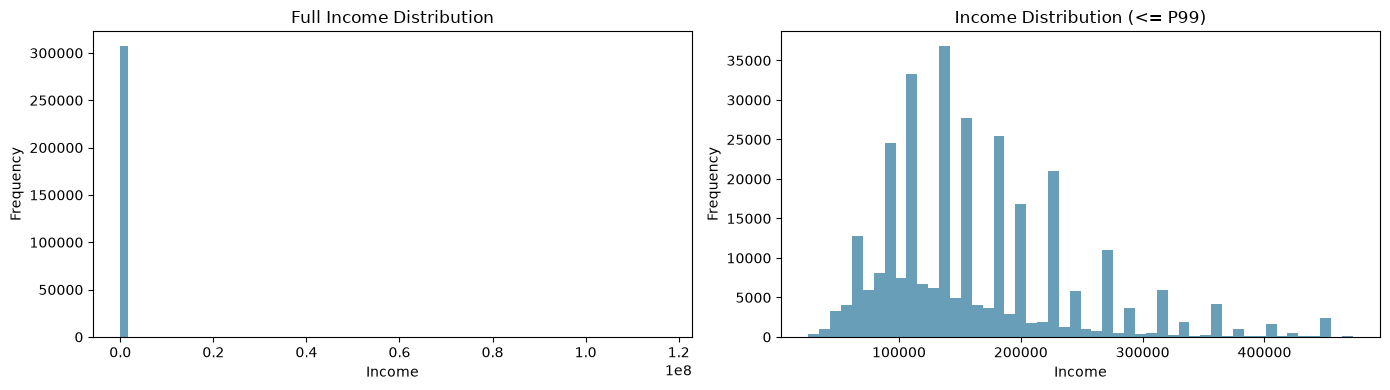

In [14]:
income = df["AMT_INCOME_TOTAL"].dropna()

p99 = income.quantile(0.99)

print(f"Mean Income: {income.mean():,.2f}")
print(f"Median Income: {income.median():,.2f}")
print(f"Skewness: {income.skew():.2f}")
print(f"99th Percentile: {p99:,.2f}")
print(f"Maximum Income: {income.max():,.2f}")
print(f"Observations above P99: {(income > p99).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Full income distribution
axes[0].hist(income, bins=70, color= "#689EB8")
axes[0].set_title("Full Income Distribution")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Frequency")

# Income distribution up to the 99th percentile
axes[1].hist(
    income[income <= p99],
    bins=50,
    color="#689EB8",
)

axes[1].set_title("Income Distribution (<= P99)")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


### 3.3. Extreme Income Investigation

The income distribution is highly right-skewed.

A small number of applicants have very high income values.

In this section, we will:
- Count applicants with extreme income values.
- Review the highest income observations.
- Compare income and credit amounts.
- Identify possible data quality issues.

We will not remove or cap any values at this stage.


In [15]:
income_thresholds = {
    "Above P99" : income.quantile(0.99),
    "Above 1 Million": 1_000_000,
    "Above 5 Million": 5_000_000,
    "Above 10 Million": 10_000_000,
}

income_extreme_summary = pd.DataFrame([
    {
        "threshold": name,
        "income_limit": limit,
        "applicant_count": (income > limit).sum(),
        "applicant_pct": (income > limit).mean() * 100,
    }
    for name, limit in income_thresholds.items()
])

display(income_extreme_summary)

,threshold,income_limit,applicant_count,applicant_pct
0,Above P99,"472,500.00",3014,0.98
1,Above 1 Million,"1,000,000.00",250,0.08
2,Above 5 Million,"5,000,000.00",5,0.00
3,Above 10 Million,"10,000,000.00",3,0.00


Let’s examine the 10 applications with the highest income.

In [16]:
income_columns = [
    "SK_ID_CURR",
    "TARGET",
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "CREDIT_INCOME_RATIO"
]

top_income_applicants = df.nlargest(
    10,
    "AMT_INCOME_TOTAL"
)[income_columns]

display(top_income_applicants)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,CREDIT_INCOME_RATIO
7764,114967,1,Cash loans,"117,000,000.00","562,491.00",0.00
204782,336147,0,Cash loans,"18,000,090.00","675,000.00",0.04
246377,385674,0,Cash loans,"13,500,000.00","1,400,503.50",0.10
89978,190160,0,Cash loans,"9,000,000.00","1,431,531.00",0.16
136634,252084,0,Cash loans,"6,750,000.00","790,830.00",0.12
89940,219563,0,Revolving loans,"4,500,000.00","2,250,000.00",0.50
182597,317748,0,Cash loans,"4,500,000.00","835,380.00",0.19
212778,337151,0,Cash loans,"4,500,000.00","450,000.00",0.10
303899,432980,0,Cash loans,"4,500,000.00","1,755,000.00",0.39
177899,310601,0,Cash loans,"3,950,059.50","675,000.00",0.17



### 3.4. Income Outlier Sensitivity Analysis

A few applicants have extremely high income values.

We will compare income statistics under different scenarios.

Our goals are:
- Measure the effect of extreme values on the mean.
- Compare the median and standard deviation.
- Understand how the skewness changes.

These scenarios are for analysis only. We will keep the original data unchanged.


In [17]:
income_scenarios = {
    "Full Dataset": income,
    "Without Maximum": income.drop(income.idxmax()),
    "Income <= 10M": income[income <= 10_000_000],
    "Income <= P99": income[income <= p99],
}

income_sensitivity = pd.DataFrame([
    {
        "scenario": name,
        "count": len(values),
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(),
        "skewness": values.skew(),
        "max": values.max(),
    }
    for name, values in income_scenarios.items()
])

display(income_sensitivity.round(2))

,scenario,count,mean,median,std,skewness,max
0,Full Dataset,307511,"168,797.92","147,150.00","237,123.15",391.56,"117,000,000.00"
1,Without Maximum,307510,"168,417.99","147,150.00","108,811.81",26.98,"18,000,090.00"
2,Income <= 10M,307508,"168,316.65","147,150.00","101,133.98",8.33,"9,000,000.00"
3,Income <= P99,304497,"162,992.35","144,000.00","77,646.11",1.18,"472,500.00"



### 3.5. Financial Feature Distributions

We will explore the distributions of important financial features.

Our goals are:
- Understand the shape of each distribution.
- Identify skewed features and extreme values.
- Compare the mean and median.
- Review the amount of available data.

We will use the 99th percentile to improve chart readability.

No observations will be removed from the original dataset.


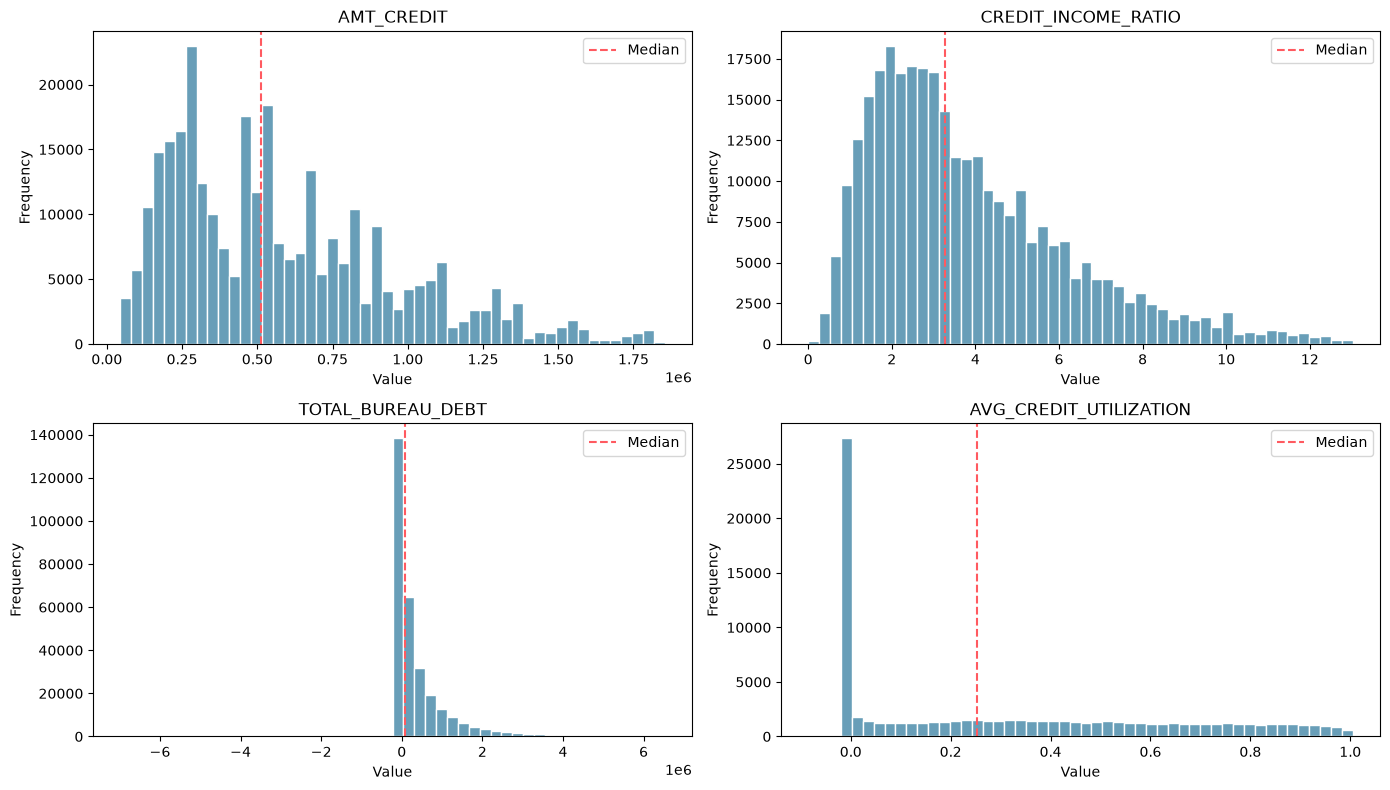

In [18]:
financial_features = [
    "AMT_CREDIT",
    "CREDIT_INCOME_RATIO",
    "TOTAL_BUREAU_DEBT",
    "AVG_CREDIT_UTILIZATION",
]

fig, axes = plt.subplots(2, 2, figsize=(14,8))

for ax, col in zip(axes.flat, financial_features):
    values = df[col].dropna()
    p99_value = values.quantile(0.99)

    # Limit the chart range to the 99th percentile
    plot_values = values[values <= p99_value]

    ax.hist(
        plot_values,
        bins=50,
        color="#689EB8",
        edgecolor = "white"
    )

    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

    ax.axvline(
        values.median(),
        color="#FF5A60",
        linestyle="--",
        label="Median",
    )

    ax.legend()

plt.tight_layout()
plt.show()


### 3.6. Bureau Debt Data Quality Analysis

The bureau debt distribution contains values close to zero and may include negative values.

In this section, we will:
- Count negative, zero, and positive debt values.
- Check their percentage in the dataset.
- Review applicants with the lowest debt values.
- Identify possible data quality issues.

We will keep the original values unchanged.


In [19]:
debt = df["TOTAL_BUREAU_DEBT"]

debt_summary = pd.DataFrame({
    "group": ["Negative", "Zero", "Positive", "Missing"],
    "count": [
        debt.lt(0).sum(),
        debt.eq(0).sum(),
        debt.gt(0).sum(),
        debt.isna().sum(),
    ]
})

debt_summary["percentage"] = (
    debt_summary["count"] / len(df) * 100
)

display(debt_summary)

print(f"Minimum debt: {debt.min():,.2f}")
print(f"Median debt: {debt.median():,.2f}")
print(f"Maximum debt: {debt.max():,.2f}")

assert debt_summary["count"].sum() == len(df)

,group,count,percentage
0,Negative,1296,0.42
1,Zero,121069,39.37
2,Positive,185146,60.21
3,Missing,0,0.00


Minimum debt: -6,981,558.21
Median debt: 87,583.50
Maximum debt: 334,498,331.20


Let's check the lowest debt values:

In [20]:

debt_columns = [
    "SK_ID_CURR",
    "TARGET",
    "BUREAU_CREDIT_COUNT",
    "TOTAL_BUREAU_CREDIT",
    "TOTAL_BUREAU_DEBT",
]

lowest_debt_applicants = df.nsmallest(
    10,
    "TOTAL_BUREAU_DEBT"
)[debt_columns]

display(lowest_debt_applicants)


,SK_ID_CURR,TARGET,BUREAU_CREDIT_COUNT,TOTAL_BUREAU_CREDIT,TOTAL_BUREAU_DEBT
207892,316058,0,8,"51,651,270.00","-6,981,558.21"
82701,187109,0,3,0.00,"-3,112,461.13"
139678,268156,0,5,"4,708,908.00","-2,737,764.72"
104857,237440,0,8,"4,275,000.00","-2,176,471.85"
43653,146988,0,2,"679,500.00","-2,167,229.34"
71458,160759,0,9,"1,367,721.00","-1,999,478.48"
71882,198204,0,8,"3,645,813.42","-1,765,825.20"
256803,367088,0,5,"7,057,687.50","-1,122,011.28"
241952,397243,0,8,"16,364,539.35","-807,549.12"
104486,237376,0,13,"2,535,361.65","-791,768.88"



### 3.7. Negative Bureau Debt Investigation

Some applicants have negative total bureau debt.

We will check the source records for the applicant with the lowest total debt.

Our goals are:
- Review the original bureau records.
- Identify negative debt amounts.
- Compare the source total with the customer-level feature.

We will not change any debt values in this step.


In [21]:
# Select the applicant with the lowest bureau debt
customer_id = int(
    lowest_debt_applicants.iloc[0]["SK_ID_CURR"]
)

query = text("""
    SELECT
        SK_ID_BUREAU,
        CREDIT_ACTIVE,
        AMT_CREDIT_SUM,
        AMT_CREDIT_SUM_DEBT
    FROM core.bureau
    WHERE SK_ID_CURR = :customer_id
    ORDER BY AMT_CREDIT_SUM_DEBT ASC;
""")

with engine.connect() as connection:
    bureau_records = pd.read_sql_query(
        query,
        connection,
        params={"customer_id": customer_id},
    )

display(bureau_records)

,SK_ID_BUREAU,CREDIT_ACTIVE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT
0,5262220,Active,0.00,"-4,705,600.32"
1,5262219,Active,0.00,"-2,273,021.73"
2,5262217,Closed,0.00,"-2,727.72"
3,5262218,Active,0.00,-208.44
4,5262221,Active,0.00,0.00
5,5262222,Closed,"20,790,000.00",0.00
6,5262223,Closed,"29,713,500.00",0.00
7,5262224,Active,"1,147,770.00",0.00


In [22]:

source_debt = pd.to_numeric(
    bureau_records["AMT_CREDIT_SUM_DEBT"],
    errors="coerce",
)

source_total = source_debt.sum()

customer_total = df.loc[
    df["SK_ID_CURR"] == customer_id,
    "TOTAL_BUREAU_DEBT",
].iloc[0]

print(f"Applicant ID: {customer_id}")
print(f"Bureau records: {len(bureau_records):,}")
print(f"Negative debt records: {source_debt.lt(0).sum():,}")
print(f"Missing debt records: {source_debt.isna().sum():,}")

print(f"\nSource Total Debt: {source_total:,.2f}")
print(f"Customer Total Debt: {customer_total:,.2f}")
print(f"Difference: {source_total - customer_total:,.2f}")


Applicant ID: 316058
Bureau records: 8
Negative debt records: 4
Missing debt records: 0

Source Total Debt: -6,981,558.21
Customer Total Debt: -6,981,558.21
Difference: -0.00



### 3.8. Understanding Zero Bureau Debt

Some applicants have zero total bureau debt.

However, zero debt does not always mean that the applicant has no credit history.

In this section, we will:
- Identify applicants without bureau records.
- Identify applicants with bureau records and zero total debt.
- Compare the size of these groups.

We will not modify the original data.


In [23]:
# Select applicants with zero total bureau debt
zero_debt_df = df.loc[
    df["TOTAL_BUREAU_DEBT"].eq(0)
].copy()

# Classify applicants by bureau history
zero_debt_df["bureau_history_group"] = "Has Bureau Records"

zero_debt_df.loc[
    zero_debt_df["BUREAU_CREDIT_COUNT"].eq(0),
    "bureau_history_group"
] = "No Bureau Records"

zero_debt_df.loc[
    zero_debt_df["BUREAU_CREDIT_COUNT"].isna(),
    "bureau_history_group"
] = "Unknown Bureau History"

# Calculate group statistics
zero_debt_summary = (
    zero_debt_df
    .groupby("bureau_history_group")
    .agg(
        applicant_count = ("SK_ID_CURR", "count"),
        avg_bureau_credits = ("BUREAU_CREDIT_COUNT", "mean"),
    )
    .reset_index()
)

zero_debt_summary["percentage"] = (
    zero_debt_summary["applicant_count"]
    / len(zero_debt_df)
    * 100
)

display(zero_debt_summary)

print(f"Total zero-debt applicants: {len(zero_debt_df):,}")

assert len(zero_debt_df) == 121_069
assert zero_debt_summary["applicant_count"].sum() == len(zero_debt_df)

,bureau_history_group,applicant_count,avg_bureau_credits,percentage
0,Has Bureau Records,77049,3.35,63.64
1,No Bureau Records,44020,0.00,36.36


Total zero-debt applicants: 121,069



### 3.9. Bureau Debt Completeness Analysis

Some applicants have bureau records but zero total debt.

We will check their source debt values.

Our goals are:
- Identify applicants with only zero debt values.
- Find applicants with missing debt amounts.
- Check if positive and negative debts cancel each other.

This analysis will help us understand the meaning of zero debt.
We will keep the original dataset unchanged.


In [24]:

query = text("""
    WITH debt_counts AS (
        SELECT
            b.SK_ID_CURR,
            COUNT_BIG(*) AS record_count,
            SUM(CASE WHEN b.AMT_CREDIT_SUM_DEBT IS NULL THEN 1 ELSE 0 END) AS missing_count,
            SUM(CASE WHEN b.AMT_CREDIT_SUM_DEBT = 0 THEN 1 ELSE 0 END) AS zero_count,
            SUM(CASE WHEN b.AMT_CREDIT_SUM_DEBT > 0 THEN 1 ELSE 0 END) AS positive_count,
            SUM(CASE WHEN b.AMT_CREDIT_SUM_DEBT < 0 THEN 1 ELSE 0 END) AS negative_count
        FROM core.bureau AS b
        INNER JOIN core.applications AS a
            ON b.SK_ID_CURR = a.SK_ID_CURR
        WHERE a.DATASET_TYPE = 'TRAIN'
        GROUP BY b.SK_ID_CURR
        HAVING COALESCE(SUM(b.AMT_CREDIT_SUM_DEBT), 0) = 0
    ),
    debt_patterns AS (
        SELECT
            SK_ID_CURR,
            CASE
                WHEN missing_count = record_count
                    THEN 'All Debt Values Missing'
                WHEN positive_count > 0 AND negative_count > 0
                    THEN 'Positive and Negative Offset'
                WHEN missing_count > 0
                    THEN 'Zero and Missing Values'
                ELSE 'All Recorded Values Zero'
            END AS debt_pattern
        FROM debt_counts
    )
    SELECT
        debt_pattern,
        COUNT_BIG(*) AS applicant_count
    FROM debt_patterns
    GROUP BY debt_pattern
    ORDER BY applicant_count DESC;
""")

with engine.connect() as connection:
    debt_pattern_summary = pd.read_sql_query(query, connection)

debt_pattern_summary["percentage"] = (
    debt_pattern_summary["applicant_count"]
    / debt_pattern_summary["applicant_count"].sum()
    * 100
)

display(debt_pattern_summary)

print(
    "Total applicants with bureau history and zero debt:",
    f"{debt_pattern_summary['applicant_count'].sum():,}"
)


,debt_pattern,applicant_count,percentage
0,All Recorded Values Zero,44717,58.04
1,Zero and Missing Values,24972,32.41
2,All Debt Values Missing,7360,9.55


Total applicants with bureau history and zero debt: 77,049



### 3.10. Bureau Debt Completeness and Payment Difficulty

We found that some applicants have missing bureau debt information.

In this section, we will:
- Group applicants by bureau debt data availability.
- Calculate the payment difficulty rate for each group.
- Compare applicants with complete and incomplete debt records.

This is an exploratory analysis. It does not show a causal relationship.


In [25]:

query = text("""
    WITH bureau_profile AS (
        SELECT
            SK_ID_CURR,
            COUNT_BIG(*) AS bureau_records,
            SUM(CASE WHEN AMT_CREDIT_SUM_DEBT IS NULL THEN 1 ELSE 0 END) AS missing_debt,
            SUM(CASE WHEN AMT_CREDIT_SUM_DEBT > 0 THEN 1 ELSE 0 END) AS positive_debt,
            SUM(CASE WHEN AMT_CREDIT_SUM_DEBT < 0 THEN 1 ELSE 0 END) AS negative_debt,
            COALESCE(SUM(AMT_CREDIT_SUM_DEBT), 0) AS total_debt
        FROM core.bureau
        GROUP BY SK_ID_CURR
    ),
    applicant_groups AS (
        SELECT
            a.SK_ID_CURR,
            a.TARGET,
            CASE
                WHEN b.SK_ID_CURR IS NULL
                    THEN 'No Bureau Records'
                WHEN b.total_debt < 0
                    THEN 'Negative Total Debt'
                WHEN b.total_debt > 0
                    THEN 'Positive Total Debt'
                WHEN b.missing_debt = b.bureau_records
                    THEN 'Zero - All Missing'
                WHEN b.positive_debt > 0 AND b.negative_debt > 0
                    THEN 'Zero - Offsetting Balances'
                WHEN b.missing_debt > 0
                    THEN 'Zero - Partially Missing'
                ELSE 'Zero - All Recorded Zero'
            END AS debt_data_group
        FROM core.applications AS a
        LEFT JOIN bureau_profile AS b
            ON a.SK_ID_CURR = b.SK_ID_CURR
        WHERE a.DATASET_TYPE = 'TRAIN'
    )
    SELECT
        debt_data_group,
        COUNT_BIG(*) AS applicant_count,
        SUM(CAST(TARGET AS BIGINT)) AS difficulty_count,
        CAST(
            100.0 * SUM(CAST(TARGET AS BIGINT))
            / NULLIF(COUNT_BIG(*), 0)
            AS DECIMAL(10, 2)
        ) AS difficulty_rate_pct
    FROM applicant_groups
    GROUP BY debt_data_group
    ORDER BY applicant_count DESC;
""")

with engine.connect() as connection:
    debt_target_summary = pd.read_sql_query(query, connection)

display(debt_target_summary)

print(
    "Total applications:",
    f"{debt_target_summary['applicant_count'].sum():,}"
)


,debt_data_group,applicant_count,difficulty_count,difficulty_rate_pct
0,Positive Total Debt,185146,15927,8.60
1,Zero - All Recorded Zero,44717,2682,6.00
2,No Bureau Records,44020,4457,10.12
3,Zero - Partially Missing,24972,1214,4.86
4,Zero - All Missing,7360,494,6.71
5,Negative Total Debt,1296,51,3.94


Total applications: 307,511



## 4. Missing Value Analysis

### 4.1. Missing Value Overview

We will identify missing values in the dataset and review their patterns.

Our goals are:
- Calculate missing value percentages.
- Identify features with high missing rates.
- Understand possible reasons for missing values.
- Select suitable preprocessing strategies.

We will keep useful features when their missing values can be handled safely.


In [26]:
def missing_values_table(dataframe):
    missing_df = pd.DataFrame({
        "missing_count" : dataframe.isna().sum(),
        "missing_pct" : dataframe.isna().mean() * 100,
    })

    missing_df = missing_df[missing_df["missing_count"] > 0]

    return missing_df.sort_values("missing_pct", ascending=False)

missing_summary = missing_values_table(X_eda)

print(f"Total features: {X_eda.shape[1]}")
print(f"Features with missing values: {len(missing_summary)}")
print(f"Complete features: {X_eda.shape[1] - len(missing_summary)}")

display(missing_summary.round(2))

# Group features by missing percentage
missing_bands = pd.cut(
    missing_summary["missing_pct"],
    bins=[0, 5, 20, 50, 80, 100],
    labels=["0-5%", "5-20%", "20-50%", "50-80%", "80-100%"],
    include_lowest=True,
)

missing_band_summary = (
    missing_bands.value_counts()
    .sort_index()
    .to_frame("feature_count")
)

display(missing_band_summary)

Total features: 59
Features with missing values: 30
Complete features: 29


,missing_count,missing_pct
AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT,289629,94.18
AVG_POS_DPD_WHEN_DELINQUENT,252828,82.22
MAX_CREDIT_UTILIZATION,221475,72.02
AVG_CREDIT_UTILIZATION,221475,72.02
CREDIT_CARD_DELINQUENT_MONTH_RATE,220606,71.74
AVG_CREDIT_CARD_BALANCE,220606,71.74
AVG_CREDIT_LIMIT,220606,71.74
MAX_CREDIT_CARD_BALANCE,220606,71.74
MAX_CREDIT_CARD_DPD,220606,71.74
AVG_LATE_PAYMENT_DAYS,152512,49.60


,feature_count
missing_pct,
0-5%,4
5-20%,15
20-50%,2
50-80%,7
80-100%,2



### 4.2. Structural Missingness

Some features are missing because an applicant has no related credit history or late payment events.

We will compare missing values with historical activity indicators.

This helps us distinguish expected missing values from missing information.

We will not fill missing values in this step.


In [27]:
X_eda.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AGE_YEARS,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,ANNUITY_CREDIT_RATIO,DAYS_EMPLOYED,DAYS_EMPLOYED_ANOMALY,BUREAU_CREDIT_COUNT,ACTIVE_BUREAU_CREDIT_COUNT,CLOSED_BUREAU_CREDIT_COUNT,TOTAL_BUREAU_CREDIT,TOTAL_BUREAU_DEBT,TOTAL_BUREAU_OVERDUE,MAX_CREDIT_DAY_OVERDUE,DAYS_SINCE_MOST_RECENT_BUREAU_CREDIT,BUREAU_DEBT_CREDIT_RATIO,PREVIOUS_APPLICATION_COUNT,PREVIOUS_APPROVED_COUNT,PREVIOUS_REFUSED_COUNT,PREVIOUS_APPROVAL_RATE,AVG_PREVIOUS_APPLICATION_AMOUNT,AVG_PREVIOUS_CREDIT_AMOUNT,MAX_PREVIOUS_CREDIT_AMOUNT,DAYS_SINCE_LAST_PREVIOUS_APPLICATION,PAYMENT_EVENT_COUNT,LATE_PAYMENT_COUNT,LATE_PAYMENT_RATE,AVG_LATE_PAYMENT_DAYS,MAX_LATE_PAYMENT_DAYS,UNDERPAYMENT_COUNT,UNDERPAYMENT_RATE,TOTAL_EXPECTED_PAYMENT,TOTAL_ACTUAL_PAYMENT,TOTAL_PAYMENT_SHORTFALL,POS_CONTRACT_COUNT,POS_MONTH_COUNT,POS_DELINQUENT_MONTH_RATE,MAX_POS_DPD,AVG_POS_DPD_WHEN_DELINQUENT,POS_DELINQUENT_MONTH_COUNT,POS_DEFAULT_DELINQUENT_MONTH_COUNT,CREDIT_CARD_COUNT,CREDIT_CARD_MONTH_COUNT,AVG_CREDIT_CARD_BALANCE,MAX_CREDIT_CARD_BALANCE,AVG_CREDIT_LIMIT,AVG_CREDIT_UTILIZATION,MAX_CREDIT_UTILIZATION,CREDIT_CARD_DELINQUENT_MONTH_RATE,MAX_CREDIT_CARD_DPD,AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT
0,Cash loans,F,Y,Y,2,33.01,"135,000.00","770,292.00","30,676.50","688,500.00",5.71,0.23,0.04,-529.00,0,19,8,11,"2,348,584.20","370,197.00",0.00,0.00,41.00,0.16,9,7,2,0.78,"81,194.50","92,679.00","148,342.50",391.00,63,2,0.03,3.00,4.00,2,0.03,"713,654.37","700,641.77","13,012.60",7,67,0.00,0.00,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Cash loans,F,N,Y,0,42.65,"225,000.00","545,040.00","19,705.50","450,000.00",2.42,0.09,0.04,-130.00,0,7,2,5,"727,019.46","229,616.42",0.00,0.00,49.00,0.32,4,4,0,1.00,"34,283.25","144,887.62","450,000.00",507.00,32,4,0.12,1.75,3.00,0,0.00,"156,535.79","156,535.79",0.00,3,34,0.00,0.00,NaN,0,0,1,17,0.00,0.00,"450,000.00",0.00,0.00,0.00,0.00,NaN
2,Cash loans,F,Y,N,0,29.89,"90,000.00","288,873.00","14,805.00","238,500.00",3.21,0.16,0.05,-214.00,0,4,3,1,"1,161,270.72",0.00,0.00,0.00,970.00,0.00,10,7,3,0.70,"34,202.25","182,817.45","765,000.00",49.00,78,0,0.00,NaN,NaN,0,0.00,"527,654.83","527,654.83",0.00,6,39,0.00,0.00,NaN,0,0,1,21,"191,020.91","318,301.34","315,000.00",0.61,1.01,0.00,0.00,NaN
3,Cash loans,M,Y,Y,1,30.98,"207,000.00","473,760.00","51,151.50","450,000.00",2.29,0.25,0.11,-542.00,0,4,0,4,"245,407.50",0.00,0.00,0.00,"1,506.00",0.00,5,4,0,0.80,"131,064.30","129,141.90","360,000.00",419.00,32,8,0.25,25.00,95.00,16,0.50,"342,454.41","251,592.57","90,861.84",3,31,0.23,77.00,27.43,7,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Cash loans,M,Y,Y,2,42.97,"256,500.00","824,823.00","24,246.00","688,500.00",3.22,0.09,0.03,"-3,022.00",0,8,1,7,"1,873,995.30","452,916.00",0.00,0.00,577.00,0.24,5,4,1,0.80,"45,674.45","42,859.80","103,635.00",933.00,27,3,0.11,8.33,21.00,2,0.07,"239,017.50","224,636.27","14,381.24",4,29,0.00,0.00,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
missing_checks = {
    "AVG_CREDIT_UTILIZATION" : "CREDIT_CARD_COUNT",
    "AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT" : "CREDIT_CARD_DELINQUENT_MONTH_RATE",
    "AVG_POS_DPD_WHEN_DELINQUENT" : "POS_DELINQUENT_MONTH_RATE",
    "AVG_LATE_PAYMENT_DAYS" : "LATE_PAYMENT_RATE",
}

results = []

for feature, indicator in missing_checks.items():
    missing = df[feature].isna()
    no_history_or_event = df[indicator].isna() | df[indicator].eq(0)

    results.append({
        "feature": feature,
        "missing_total": int(missing.sum()),
        "missing_without_history_or_event": int(
            (missing & no_history_or_event).sum()
        ),
        "missing_despite_history_or_event": int(
            (missing & ~no_history_or_event).sum()
        ),
    })

structural_missing_summary = pd.DataFrame(results)

display(structural_missing_summary)

,feature,missing_total,missing_without_history_or_event,missing_despite_history_or_event
0,AVG_CREDIT_UTILIZATION,221475,220606,869
1,AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT,289629,289629,0
2,AVG_POS_DPD_WHEN_DELINQUENT,252828,252828,0
3,AVG_LATE_PAYMENT_DAYS,152512,152512,0



## 5. Target Analysis

### 5.1. Categorical Features and Payment Difficulty

We will compare payment difficulty rates across categorical features.

Our goals are:
- Calculate the number of applicants in each group.
- Compare payment difficulty rates.
- Identify useful patterns for feature engineering.

These results show associations, not causal relationships.


In [29]:
categorical_features = [
    "NAME_CONTRACT_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "DAYS_EMPLOYED_ANOMALY",
]

target_summary_list = []

for col in categorical_features:
    summary = (
        df.groupby(col, dropna=False)["TARGET"]
        .agg(
            applicant_count="count",
            difficulty_count="sum",
            difficulty_rate="mean",
        )
        .reset_index()
        .rename(columns={col: "category"})
    )

    summary["difficulty_rate"] *= 100
    summary.insert(0, "feature", col)

    target_summary_list.append(summary)

categorical_target_summary = pd.concat(
    target_summary_list,
    ignore_index=True,
)


display(categorical_target_summary.round(2))

,feature,category,applicant_count,difficulty_count,difficulty_rate
0,NAME_CONTRACT_TYPE,Cash loans,278232,23221,8.35
1,NAME_CONTRACT_TYPE,Revolving loans,29279,1604,5.48
2,FLAG_OWN_CAR,N,202924,17249,8.50
3,FLAG_OWN_CAR,Y,104587,7576,7.24
4,FLAG_OWN_REALTY,N,94199,7842,8.32
5,FLAG_OWN_REALTY,Y,213312,16983,7.96
6,DAYS_EMPLOYED_ANOMALY,0,252137,21835,8.66
7,DAYS_EMPLOYED_ANOMALY,1,55374,2990,5.40



### 5.2. Numerical Features and Payment Difficulty

We will compare numerical features between applicants with and without payment difficulty.

We will focus on:
- Median values for each target group.
- Missing value percentages.
- Important differences in financial and payment behavior.

These comparisons will help us plan feature engineering.


In [31]:

selected_num_features = [
    "AGE_YEARS",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "BUREAU_CREDIT_COUNT",
    "BUREAU_DEBT_CREDIT_RATIO",
    "LATE_PAYMENT_RATE",
    "POS_DELINQUENT_MONTH_RATE",
    "AVG_CREDIT_UTILIZATION",
    "CREDIT_CARD_DELINQUENT_MONTH_RATE",
]

target_0 = df.loc[df["TARGET"] == 0]
target_1 = df.loc[df["TARGET"] == 1]

num_target_summary = pd.DataFrame({
    "feature": selected_num_features,
    "median_target_0": [
        target_0[col].median() for col in selected_num_features
    ],
    "median_target_1": [
        target_1[col].median() for col in selected_num_features
    ],
    "missing_pct_0": [
        target_0[col].isna().mean() * 100
        for col in selected_num_features
    ],
    "missing_pct_1": [
        target_1[col].isna().mean() * 100
        for col in selected_num_features
    ],
})

num_target_summary["median_difference"] = (
    num_target_summary["median_target_1"]
    - num_target_summary["median_target_0"]
)

display(num_target_summary.round(3))


,feature,median_target_0,median_target_1,missing_pct_0,missing_pct_1,median_difference
0,AGE_YEARS,43.47,39.10,0.00,0.00,-4.37
1,AMT_INCOME_TOTAL,"148,500.00","135,000.00",0.00,0.00,"-13,500.00"
2,AMT_CREDIT,"517,788.00","497,520.00",0.00,0.00,"-20,268.00"
3,CREDIT_INCOME_RATIO,3.27,3.25,0.00,0.00,-0.01
4,ANNUITY_INCOME_RATIO,0.16,0.17,0.00,0.00,0.01
5,BUREAU_CREDIT_COUNT,4.00,3.00,0.00,0.00,-1.00
6,BUREAU_DEBT_CREDIT_RATIO,0.20,0.35,14.35,18.31,0.15
7,LATE_PAYMENT_RATE,0.02,0.05,5.28,3.83,0.03
8,POS_DELINQUENT_MONTH_RATE,0.00,0.00,5.96,4.85,0.00
9,AVG_CREDIT_UTILIZATION,0.23,0.49,72.19,70.07,0.26



## 6. Feature Engineering

### 6.1. Historical Behavior Features

We will create new features from historical credit and payment data.

Our goals are:
- Identify applicants with historical records.
- Measure the share of active bureau credits.
- Measure the rate of refused previous applications.
- Improve the information available to our models.

We will use simple and reproducible calculations.
No target information will be used to create these features.


In [ ]:
def engineer_history_features(dataframe):
    data = dataframe.copy()

    history_features = {
        "HAS_BUREAU_HISTORY": "BUREAU_CREDIT_COUNT",
        "HAS_PREVIOUS_APPLICATIONS": "PREVIOUS_APPLICATION_COUNT",
        "HAS_INSTALLMENT_HISTORY": "PAYMENT_EVENT_COUNT",
        "HAS_POS_HISTORY": "POS_CONTRACT_COUNT",
        "HAS_CREDIT_CARD_HISTORY": "CREDIT_CARD_COUNT",
    }

    for new_col, source_col in history_features.items():
        data[new_col] = (
            data[source_col]
            .fillna(0)
            .gt(0)
            .astype("int8")
        )

    # When the denominator is zero, we leave the ratio as NaN.
    
    bureau_count = data["BUREAU_CREDIT_COUNT"].where(
        data["BUREAU_CREDIT_COUNT"].gt(0)
    )

    data["BUREAU_ACTIVE_SHARE"] = (
        data["ACTIVE_BUREAU_CREDIT_COUNT"] / bureau_count
    )

    previous_count = data["PREVIOUS_APPLICATION_COUNT"].where(
        data["PREVIOUS_APPLICATION_COUNT"].gt(0)
    )

    data["PREVIOUS_REFUSAL_RATE"] = (
        data["PREVIOUS_REFUSED_COUNT"] / previous_count
    )

    return data

df_fe = engineer_history_features(df)

    

In [33]:

new_features = [
    "HAS_BUREAU_HISTORY",
    "HAS_PREVIOUS_APPLICATIONS",
    "HAS_INSTALLMENT_HISTORY",
    "HAS_POS_HISTORY",
    "HAS_CREDIT_CARD_HISTORY",
    "BUREAU_ACTIVE_SHARE",
    "PREVIOUS_REFUSAL_RATE",
]

print(f"Original dataset: {df.shape}")
print(f"Engineered dataset: {df_fe.shape}")

feature_summary = pd.DataFrame({
    "missing_pct": df_fe[new_features].isna().mean() * 100,
    "unique_values": df_fe[new_features].nunique(),
    "min": df_fe[new_features].min(),
    "max": df_fe[new_features].max(),
})

display(feature_summary.round(3))


Original dataset: (307511, 62)
Engineered dataset: (307511, 69)


,missing_pct,unique_values,min,max
HAS_BUREAU_HISTORY,0.00,2,0.00,1.00
HAS_PREVIOUS_APPLICATIONS,0.00,2,0.00,1.00
HAS_INSTALLMENT_HISTORY,0.00,2,0.00,1.00
HAS_POS_HISTORY,0.00,2,0.00,1.00
HAS_CREDIT_CARD_HISTORY,0.00,2,0.00,1.00
BUREAU_ACTIVE_SHARE,14.31,296,0.00,1.00
PREVIOUS_REFUSAL_RATE,5.35,397,0.00,1.00



### 6.2. Financial Ratio Features

We will create new financial features using credit, income, and historical balance information.

Our goals are:
- Compare credit amounts with goods prices.
- Measure historical bureau debt relative to income.
- Measure credit card balances relative to income.

These features may help the model understand financial burden.

We will keep missing values and avoid division by zero.


In [34]:
def engineer_financial_features(dataframe):
    data = dataframe.copy()

    # When the denominator is zero, we leave the ratio as NaN.

    income = data["AMT_INCOME_TOTAL"].where(
        data["AMT_INCOME_TOTAL"].gt(0)
    )

    goods_price = data["AMT_GOODS_PRICE"].where(
        data["AMT_GOODS_PRICE"].gt(0)
    )

    data["CREDIT_GOODS_RATIO"] = (
        data["AMT_CREDIT"] / goods_price
    )

    data["BUREAU_DEBT_INCOME_RATIO"] = (
        data["TOTAL_BUREAU_DEBT"] / income
    )

    data["CARD_BALANCE_INCOME_RATIO"] = (
        data["AVG_CREDIT_CARD_BALANCE"] / income
    )

    return data

df_fe = engineer_financial_features(df_fe)

In [35]:

financial_new_features = [
    "CREDIT_GOODS_RATIO",
    "BUREAU_DEBT_INCOME_RATIO",
    "CARD_BALANCE_INCOME_RATIO",
]

financial_fe_summary = pd.DataFrame({
    "missing_pct": (
        df_fe[financial_new_features].isna().mean() * 100
    ),
    "median": df_fe[financial_new_features].median(),
    "p99": df_fe[financial_new_features].quantile(0.99),
    "max": df_fe[financial_new_features].max(),
})

print(f"Engineered dataset shape: {df_fe.shape}")

display(financial_fe_summary.round(3))


Engineered dataset shape: (307511, 72)


,missing_pct,median,p99,max
CREDIT_GOODS_RATIO,0.09,1.12,1.48,6.00
BUREAU_DEBT_INCOME_RATIO,0.00,0.61,32.37,"1,651.84"
CARD_BALANCE_INCOME_RATIO,71.74,0.16,3.38,12.48



## 7. Feature Selection

### 7.1. Train and Holdout Split

We will split the dataset before selecting features.

Our goals are:
- Keep the target distribution similar in both datasets.
- Use the development set for feature selection and model training.
- Keep the holdout set for final model evaluation.
- Prevent data leakage.

We will not use holdout data to select features or tune models.


In [37]:
excluded_cols = [
    "SK_ID_CURR",
    "DATASET_TYPE",
    "TARGET",
    "CODE_GENDER",
]

feature_cols = [
    col for col in df_fe.columns
    if col not in excluded_cols
]

X = df_fe[feature_cols].copy()
y = df_fe["TARGET"].astype("int8")

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Total candidate features: {X.shape[1]}")
print(f"Development set: {X_train.shape}")
print(f"Holdout set: {X_holdout.shape}")

split_summary = pd.DataFrame({
    "dataset": ["Development", "Holdout"],
    "applications": [len(y_train), len(y_holdout)],
    "difficulty_count": [y_train.sum(), y_holdout.sum()],
    "difficulty_rate_pct": [
        y_train.mean() * 100,
        y_holdout.mean() * 100,
    ],
})

display(split_summary.round(2))

Total candidate features: 68
Development set: (246008, 68)
Holdout set: (61503, 68)


,dataset,applications,difficulty_count,difficulty_rate_pct
0,Development,246008,19860,8.07
1,Holdout,61503,4965,8.07



### 7.2. Initial Feature Screening

We will review the candidate features before model training.

Our goals are:
- Find constant features.
- Identify features with high missing rates.
- Detect highly correlated numerical features.

We will use only the development dataset.

We will not remove features automatically. Final feature selection will be part of model validation.


In [39]:
# 1. Constant features
unique_counts = X_train.nunique(dropna=False)

constant_cols = unique_counts[
    unique_counts <= 1
].index.tolist()

# 2. Features with high missing rates
missing_pct = X_train.isna().mean() * 100

high_missing_cols = missing_pct[
    missing_pct >= 80
].sort_values(ascending=False)

# 3. Highly correlated numerical features
numeric_train = X_train.select_dtypes(include="number")

corr_matrix = numeric_train.corr(min_periods=1000)

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1
    )
)

corr_pairs = (
    upper_triangle
    .stack()
    .reset_index(name="correlation")
)

corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation",
]

corr_pairs["abs_correlation"] = (
    corr_pairs["correlation"].abs()
)

high_corr_pairs = (
    corr_pairs[
        corr_pairs["abs_correlation"] >= 0.95
    ]
    .sort_values("abs_correlation", ascending=False)
)

print(f"Candidate features: {X_train.shape[1]}")
print(f"Constant features: {len(constant_cols)}")
print(f"Features with >=80% missing: {len(high_missing_cols)}")
print(f"Highly correlated pairs: {len(high_corr_pairs)}")

print("\nConstant features:")
print(constant_cols)

print("\nHigh missing features:")
display(high_missing_cols.to_frame("missing_pct"))

print("\nHighly correlated feature pairs:")
display(high_corr_pairs.head(20).round(4))

Candidate features: 68
Constant features: 0
Features with >=80% missing: 2
Highly correlated pairs: 7

Constant features:
[]

High missing features:


,missing_pct
AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT,94.25
AVG_POS_DPD_WHEN_DELINQUENT,82.24



Highly correlated feature pairs:


,feature_1,feature_2,correlation,abs_correlation
2984,CREDIT_CARD_COUNT,HAS_CREDIT_CARD_HISTORY,1.00,1.00
3499,MAX_CREDIT_CARD_DPD,AVG_CREDIT_CARD_DPD_WHEN_DELINQUENT,0.99,0.99
200,AMT_CREDIT,AMT_GOODS_PRICE,0.99,0.99
2311,TOTAL_EXPECTED_PAYMENT,TOTAL_ACTUAL_PAYMENT,0.98,0.98
1585,AVG_PREVIOUS_APPLICATION_AMOUNT,AVG_PREVIOUS_CREDIT_AMOUNT,0.98,0.98
2707,MAX_POS_DPD,AVG_POS_DPD_WHEN_DELINQUENT,0.97,0.97
1403,PREVIOUS_APPROVED_COUNT,POS_CONTRACT_COUNT,0.95,0.95



### 7.3. Baseline Model

We will train a Logistic Regression model using all candidate features.

Our preprocessing pipeline will:
- Fill missing numerical values with the median.
- Fill missing categorical values with the most frequent value.
- Encode categorical features.
- Scale numerical features.

We will use a validation set from the development data.

The final holdout set will remain untouched.


In [41]:
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

categorical_features.append("DAYS_EMPLOYED_ANOMALY")

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features),
])

baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Total candidate features: {X_train.shape[1]}")

Numerical features: 64
Categorical features: 4
Total candidate features: 68


In [42]:

X_dev_train, X_dev_valid, y_dev_train, y_dev_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42,
)

print(f"Model training: {X_dev_train.shape}")
print(f"Model validation: {X_dev_valid.shape}")

baseline_pipeline.fit(X_dev_train, y_dev_train)

print("Baseline model trained successfully.")


Model training: (196806, 68)
Model validation: (49202, 68)
Baseline model trained successfully.


In [45]:
y_valid_proba = baseline_pipeline.predict_proba(
    X_dev_valid
)[:, 1]

y_valid_pred = baseline_pipeline.predict(X_dev_valid)

baseline_results = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "PR-AUC (Average Precision)",
        "Accuracy",
        "Baseline Positive Rate"
    ],
    "value": [
        roc_auc_score(y_dev_valid, y_valid_proba),
        average_precision_score(y_dev_valid, y_valid_proba),
        accuracy_score(y_dev_valid, y_valid_pred),
        y_dev_valid.mean(),
    ]
})

display(baseline_results.round(4))

,metric,value
0,ROC-AUC,0.70
1,PR-AUC (Average Precision),0.18
2,Accuracy,0.92
3,Baseline Positive Rate,0.08



#### Baseline Model — Results & Key Findings

We trained a Logistic Regression model using 68 candidate features.

The model was evaluated on the development validation set. The final holdout set was not used.

**Performance Summary**

| Metric | Score |
|---|---:|
| ROC-AUC | 0.70 |
| Average Precision (PR-AUC) | 0.18 |
| Accuracy | 0.92 |
| Positive Class Rate | 0.08 |

**Key Findings**

- **ROC-AUC (0.70):** The model can distinguish between applicants with and without payment difficulty better than random guessing.
- **Average Precision (0.18):** The model performs better than the positive class baseline of approximately 0.08.
- **Accuracy (0.92):** Accuracy is not very informative because about 92% of applicants belong to TARGET = 0.

**Conclusion**

The baseline model shows useful predictive ability, but there is room for improvement.

We will examine classification errors, compare other algorithms, and evaluate feature selection methods.

The final model will be selected based on predictive performance, reliability, and model complexity.



#### Classification Performance Analysis

We will evaluate the classification results of our baseline model.

Our goals are to:
- Calculate precision, recall, and F1-score.
- Analyze the confusion matrix.
- Understand false positive and false negative predictions.

We will use the default classification threshold of 0.50.

The final holdout set will remain untouched.


,metric,value
0,Precision,0.43
1,Recall,0.00
2,F1-Score,0.01


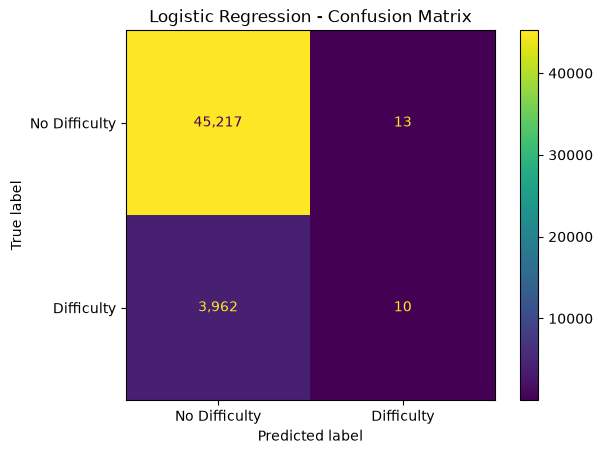

In [47]:
classification_results = pd.DataFrame({
    "metric": ["Precision", "Recall", "F1-Score"],
    "value": [
        precision_score(y_dev_valid, y_valid_pred, zero_division=0),
        recall_score(y_dev_valid, y_valid_pred, zero_division=0),
        f1_score(y_dev_valid, y_valid_pred, zero_division=0),
    ],
})

display(classification_results.round(4))

cm = confusion_matrix(
    y_dev_valid,
    y_valid_pred,
    labels=[0, 1],
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Difficulty", "Difficulty"],
)

disp.plot(values_format=",")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


#### Classification Results — Key Findings & Conclusion

The Logistic Regression model was evaluated using a classification threshold of 0.50.

**Key Findings**

- **Precision (43.48%):** The model correctly identified 10 out of 23 applicants predicted as high-risk.
- **Recall (0.25%):** The model identified only 10 out of 3,972 applicants with payment difficulty.
- **False Negatives (3,962):** Most applicants with payment difficulty were classified as low-risk.
- **False Positives (13):** Very few applicants without payment difficulty were incorrectly classified as high-risk.

**Conclusion**

The model achieved a ROC-AUC of 0.70 and an Average Precision of 0.18. These results suggest that it has some ability to rank applicants by payment difficulty risk.

However, its classification performance at the default threshold of 0.50 is very poor.

The model predicts very few applicants as high-risk and misses almost all positive cases.

**Next Steps**

- Compare different machine learning models.
- Evaluate smaller feature sets using cross-validation.
- Improve the model through hyperparameter optimization.
- Select a suitable classification threshold based on the balance between precision, recall, and business costs.

The final holdout dataset will remain untouched until the model and threshold are selected.



### 7.4. Feature Selection

#### Permutation Feature Importance

We will measure the importance of our candidate features using the baseline model.

Permutation importance shows how model performance changes when a feature is randomly shuffled.

Our goals are to:
- Identify features that support model performance.
- Find features with low predictive contribution.
- Prepare smaller feature sets for model comparison.

We will use Average Precision as the evaluation metric.

The final feature set will be selected using cross-validation.


In [50]:
# Create a stratified sample for feature importance
X_rank, _, y_rank, _ = train_test_split(
    X_dev_valid,
    y_dev_valid,
    train_size=8000,
    stratify=y_dev_valid,
    random_state=42,
)

# Calculate permutation importance
perm_result = permutation_importance(
    estimator=baseline_pipeline,
    X=X_rank,
    y=y_rank,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "feature": X_rank.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
})

feature_importance = (
    feature_importance
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

print(f"Total features: {len(feature_importance)}")
print(
    "Features with positive importance:",
    (feature_importance["importance_mean"] > 0).sum()
)

display(
    feature_importance.head(20).style.format({
        "importance_mean": "{:.4f}",
        "importance_std": "{:.4f}",
    })
)

Total features: 68
Features with positive importance: 54


,feature,importance_mean,importance_std
0,AMT_GOODS_PRICE,0.0581,0.0035
1,TOTAL_EXPECTED_PAYMENT,0.0431,0.0008
2,TOTAL_ACTUAL_PAYMENT,0.0303,0.0018
3,AVG_PREVIOUS_APPLICATION_AMOUNT,0.0245,0.0034
4,BUREAU_CREDIT_COUNT,0.0206,0.0021
5,AVG_PREVIOUS_CREDIT_AMOUNT,0.0198,0.0018
6,AMT_CREDIT,0.0189,0.0061
7,DAYS_EMPLOYED,0.0173,0.0013
8,PAYMENT_EVENT_COUNT,0.0160,0.0026
9,MAX_POS_DPD,0.0129,0.0020



#### Permutation Importance — Key Findings

The results show that credit amounts, previous applications, and historical payment features contribute to the baseline model.

AMT_GOODS_PRICE has the highest permutation importance.

Some important features are strongly correlated. Therefore, their individual importance scores may not show their full predictive value.

These results provide an initial feature ranking, not a final feature selection.

We will compare smaller feature sets using cross-validation to measure their effect on model performance.



#### Feature Selection with Cross-Validation

We will compare a full model with a reduced model.

The reduced model will select features using Extra Trees.

Feature selection and preprocessing will be fitted only on the training part of each cross-validation fold.

We will compare the models using ROC-AUC and Average Precision.

The final holdout set will not be used.


In [52]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

# Full-feature baseline
full_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

# Feature selector
selector = SelectFromModel(
    estimator=ExtraTreesClassifier(
        n_estimators=60,
        max_depth=10,
        min_samples_leaf=50,
        n_jobs=-1,
        random_state=42,
    ),
    threshold=-np.inf,
    max_features=25,
)

# Reduced-feature model
reduced_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selector", selector),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

models = {
    "Full Model": full_pipeline,
    "Reduced Model (25)": reduced_pipeline,
}

results = []

for name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
        },
        n_jobs=1,
    )

    results.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "ap_mean": scores["test_average_precision"].mean(),
        "ap_std": scores["test_average_precision"].std(),
    })

feature_selection_results = pd.DataFrame(results)

display(feature_selection_results.round(4))

,model,roc_auc_mean,roc_auc_std,ap_mean,ap_std
0,Full Model,0.70,0.00,0.18,0.00
1,Reduced Model (25),0.68,0.00,0.16,0.00



#### Feature Selection — Initial Findings

We compared Logistic Regression models using all features and 25 selected transformed features.

**Key Findings**

- The full model achieved a ROC-AUC of 0.70 and an Average Precision of 0.18.
- The reduced model achieved a ROC-AUC of 0.68 and an Average Precision of 0.16.
- Reducing the number of model inputs to 25 decreased predictive performance.

**Conclusion**

The 25-feature model is not our preferred choice at this stage.

We will test larger feature sets to find a better balance between predictive performance and model complexity.

Final feature selection will also consider stronger machine learning models.


In [53]:

feature_counts = [40, 55]

additional_results = []

for n_features in feature_counts:
    feature_selector = clone(selector).set_params(
        max_features=n_features
    )

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("selector", feature_selector),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42,
        )),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
        },
        n_jobs=1,
    )

    additional_results.append({
        "model": f"Reduced Model ({n_features})",
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "ap_mean": scores["test_average_precision"].mean(),
        "ap_std": scores["test_average_precision"].std(),
    })

additional_df = pd.DataFrame(additional_results)

comparison_df = pd.concat(
    [feature_selection_results, additional_df],
    ignore_index=True,
)

with pd.option_context(
    "display.float_format",
    "{:.4f}".format,
):
    display(comparison_df)


,model,roc_auc_mean,roc_auc_std,ap_mean,ap_std
0,Full Model,0.6994,0.0022,0.1789,0.0029
1,Reduced Model (25),0.6823,0.0021,0.1642,0.0030
2,Reduced Model (40),0.6900,0.0023,0.1709,0.0031
3,Reduced Model (55),0.6955,0.0018,0.1769,0.0030



#### Feature Selection — Final Findings

We compared Logistic Regression models with different numbers of selected features.

**Key Findings**

- The full model achieved a ROC-AUC of 0.6994 and an Average Precision of 0.1789.
- The 55-feature model achieved similar results, with a ROC-AUC of 0.6955 and an Average Precision of 0.1769.
- Models with 25 and 40 selected features showed larger performance losses.

**Conclusion**

The 55-feature model is a promising alternative to the full model.

However, these results are based only on Logistic Regression.

We will compare stronger algorithms before selecting the final features. Our goal is to build a model that balances predictive performance and simplicity.



### 7.5. Model Comparison

We will compare Logistic Regression with two gradient boosting models: LightGBM and XGBoost.

Our goals are to:
- Compare predictive performance using cross-validation.
- Evaluate ROC-AUC and Average Precision.
- Identify promising models for further optimization.

All models will use the same development dataset and cross-validation strategy.

The final holdout set will remain untouched.


In [55]:
boosting_models = {
    "LightGBM": LGBMClassifier(
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=50,
        colsample_bytree=0.8,
        verbosity=-1,
        n_jobs=4,
        random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="logloss",
        n_jobs=4,
        random_state=42,
    ),
}

boosting_results = []

for name, estimator in boosting_models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
        },
        n_jobs=1,
        error_score="raise",
    )

    boosting_results.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "ap_mean": scores["test_average_precision"].mean(),
        "ap_std": scores["test_average_precision"].std(),
    })

boosting_results_df = pd.DataFrame(boosting_results)

In [56]:
logistic_result = (
    feature_selection_results
    .loc[lambda x: x["model"] == "Full Model"]
    .copy()
)

logistic_result["model"] = "Logistic Regression"

model_comparison = pd.concat(
    [logistic_result, boosting_results_df],
    ignore_index=True,
)

model_comparison = model_comparison.sort_values(
    "ap_mean",
    ascending=False,
).reset_index(drop=True)

display(
    model_comparison.style.format({
        "roc_auc_mean": "{:.4f}",
        "roc_auc_std": "{:.4f}",
        "ap_mean": "{:.4f}",
        "ap_std": "{:.4f}",
    })
)

,model,roc_auc_mean,roc_auc_std,ap_mean,ap_std
0,LightGBM,0.7240,0.0025,0.2060,0.0016
1,XGBoost,0.7225,0.0022,0.2048,0.0016
2,Logistic Regression,0.6994,0.0022,0.1789,0.0029



#### Model Comparison — Key Findings

We compared Logistic Regression, LightGBM, and XGBoost using 3-fold stratified cross-validation.

**Key Findings**

- LightGBM achieved the highest ROC-AUC (0.7240) and Average Precision (0.2060).
- XGBoost achieved very similar results.
- Both gradient boosting models performed better than Logistic Regression.
- The Average Precision of both boosting models was higher than the positive class rate of approximately 0.08.

**Conclusion**

LightGBM is our leading model for the next stage.

However, the difference between LightGBM and XGBoost is small. We will keep both models as candidates.

Next, we will identify the most useful features and evaluate smaller feature sets.

The final holdout dataset remains untouched.



### 7.6. LightGBM Feature Importance

We will analyze feature importance using LightGBM.

Our goals are to:
- Rank the original model features.
- Identify important financial and payment behavior variables.
- Prepare smaller feature sets for model comparison.

We will use gain-based feature importance.

The ranking will be calculated using training data only. We will not use the final holdout set.


In [58]:
def prepare_lgbm_features(dataframe):
    data = dataframe.copy()

    cat_columns = data.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in cat_columns:
        data[col] = data[col].astype("category")

    return data

lgbm_importance_pipeline = Pipeline([
    (
        "prepare",
        FunctionTransformer(
            prepare_lgbm_features,
            validate=False
        ),
    ),
    (
        "model",
        clone(boosting_models["LightGBM"]).set_params(
            importance_type="gain"
        ),
    )
])

# Use only development training data
lgbm_importance_pipeline.fit(
    X_dev_train,
    y_dev_train,
)

lgbm_model = lgbm_importance_pipeline.named_steps["model"]

lgbm_importance_df = pd.DataFrame({
    "feature": X_dev_train.columns,
    "gain": lgbm_model.feature_importances_,
})

total_gain = lgbm_importance_df["gain"].sum()

lgbm_importance_df["gain_pct"] = (
    lgbm_importance_df["gain"] / total_gain * 100
)

lgbm_importance_df = (
    lgbm_importance_df
    .sort_values("gain", ascending=False)
    .reset_index(drop=True)
)

display(lgbm_importance_df.head(25).round(3))

,feature,gain,gain_pct
0,ANNUITY_CREDIT_RATIO,"16,522.17",9.21
1,DAYS_EMPLOYED,"15,055.09",8.40
2,BUREAU_DEBT_CREDIT_RATIO,"10,618.32",5.92
3,CREDIT_GOODS_RATIO,"10,507.28",5.86
4,DAYS_SINCE_MOST_RECENT_BUREAU_CREDIT,"9,599.42",5.35
5,LATE_PAYMENT_RATE,"7,933.64",4.42
6,PREVIOUS_REFUSAL_RATE,"7,299.98",4.07
7,AGE_YEARS,"6,186.45",3.45
8,TOTAL_ACTUAL_PAYMENT,"5,580.84",3.11
9,BUREAU_ACTIVE_SHARE,"5,119.17",2.85



#### Feature Importance — Key Findings

LightGBM identified several important features related to financial burden and historical credit behavior.

**Key Findings**

- ANNUITY_CREDIT_RATIO and DAYS_EMPLOYED have the highest gain importance.
- Historical debt and payment behavior features are also important.
- New features such as CREDIT_GOODS_RATIO, PREVIOUS_REFUSAL_RATE, and BUREAU_ACTIVE_SHARE appear among the top-ranked variables.

**Conclusion**

Our feature engineering process has created useful candidate features.

However, gain importance does not guarantee better validation performance.

We will compare smaller feature sets using cross-validation before making a final decision.



### 7.7. LightGBM Feature Selection

We will compare LightGBM models using different numbers of original features.

We will test 68, 50, 35, and 20 features.

In each cross-validation fold:
- Train a LightGBM model on the training data.
- Rank features using gain importance.
- Select the top features.
- Train and evaluate the reduced models.

Feature selection will not use validation or holdout data.

We will compare ROC-AUC and Average Precision.


In [59]:
feature_counts = [68, 50, 35, 20]

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    X_fold_train = prepare_lgbm_features(
        X_train.iloc[train_idx]
    )
    X_fold_valid = prepare_lgbm_features(
        X_train.iloc[valid_idx]
    )

    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    # Rank features using only fold training data
    ranking_model = clone(
        boosting_models["LightGBM"]
    ).set_params(importance_type="gain")

    ranking_model.fit(X_fold_train, y_fold_train)

    feature_ranking = pd.Series(
        ranking_model.feature_importances_,
        index=X_fold_train.columns,
    ).sort_values(ascending=False)

    for n_features in feature_counts:
        if n_features == X_fold_train.shape[1]:
            selected = X_fold_train.columns.tolist()
            model = ranking_model

        else:
            selected = feature_ranking.head(
                n_features
            ).index.tolist()

            model = clone(boosting_models["LightGBM"])

            model.fit(
                X_fold_train[selected],
                y_fold_train,
            )

        y_proba = model.predict_proba(
            X_fold_valid[selected]
        )[:, 1]

        cv_results.append({
            "fold": fold,
            "features": n_features,
            "roc_auc": roc_auc_score(
                y_fold_valid, y_proba
            ),
            "average_precision": average_precision_score(
                y_fold_valid, y_proba
            ),
        })

    print(f"Fold {fold} completed.")

cv_results_df = pd.DataFrame(cv_results)

Fold 1 completed.
Fold 2 completed.
Fold 3 completed.


In [60]:
lgbm_feature_comparison = (
    cv_results_df.groupby("features")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
    )
    .reset_index()
    .sort_values("features", ascending=False)
)

display(
    lgbm_feature_comparison.style.format({
        "roc_auc_mean": "{:.4f}",
        "roc_auc_std": "{:.4f}",
        "ap_mean": "{:.4f}",
        "ap_std": "{:.4f}",
    })
)

,features,roc_auc_mean,roc_auc_std,ap_mean,ap_std
3,68,0.7241,0.0031,0.2058,0.0040
2,50,0.7237,0.0037,0.2051,0.0033
1,35,0.7230,0.0044,0.2048,0.0037
0,20,0.7188,0.0021,0.1988,0.0029



#### Feature Selection — Key Findings

We compared LightGBM models using 68, 50, 35, and 20 features.

**Key Findings**

- The full model achieved a ROC-AUC of 0.7241 and an Average Precision of 0.2058.
- The 35-feature model achieved very similar results: 0.7230 ROC-AUC and 0.2048 Average Precision.
- The 35-feature model uses about 49% fewer input features.
- Reducing the number of features to 20 caused a larger performance loss.

**Conclusion**

The 35-feature model offers a promising balance between predictive performance and simplicity.

We will examine feature selection stability before finalizing the feature list.

The full model will remain our performance reference.



#### Feature Selection Stability

We will check whether LightGBM selects similar features across cross-validation folds.

Our goals are to:
- Identify consistently selected features.
- Review changes in feature rankings.
- Create a preliminary 35-feature list.

We will use only the development dataset.

The final holdout set will remain untouched.


In [62]:
top_n = 35
fold_selections = []

# Calculate feature importance separately in each fold
for train_idx, valid_idx in cv.split(X_train, y_train):
    X_fold = prepare_lgbm_features(
        X_train.iloc[train_idx]
    )
    y_fold = y_train.iloc[train_idx]

    model = clone(
        boosting_models["LightGBM"]
    ).set_params(importance_type="gain")

    model.fit(X_fold, y_fold)

    importance = pd.Series(
        model.feature_importances_,
        index=X_fold.columns,
    ).sort_values(ascending=False)

    fold_selections.append(
        importance.head(top_n).index.tolist()
    )

# Count how many folds selected each feature
selection_counts = Counter(
    feature
    for selected in fold_selections
    for feature in selected
)

# Train ranking model on the full development dataset
final_ranker = clone(
    boosting_models["LightGBM"]
).set_params(importance_type="gain")

final_ranker.fit(
    prepare_lgbm_features(X_train),
    y_train,
)

final_importance = pd.Series(
    final_ranker.feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False)

candidate_features_35 = (
    final_importance.head(top_n).index.tolist()
)

# Create stability summary
feature_stability = pd.DataFrame({
    "feature": candidate_features_35,
    "gain": final_importance.loc[candidate_features_35].values,
    "selected_folds": [
        selection_counts.get(feature, 0)
        for feature in candidate_features_35
    ],
})

print("Features selected in all 3 folds:")
print((feature_stability["selected_folds"] == 3).sum())

print("\nFeatures selected in at least 2 folds:")
print((feature_stability["selected_folds"] >= 2).sum())

display(feature_stability)

Features selected in all 3 folds:
30

Features selected in at least 2 folds:
32


,feature,gain,selected_folds
0,ANNUITY_CREDIT_RATIO,"21,100.17",3
1,DAYS_EMPLOYED,"18,457.34",3
2,BUREAU_DEBT_CREDIT_RATIO,"12,989.59",3
3,CREDIT_GOODS_RATIO,"12,051.49",3
4,DAYS_SINCE_MOST_RECENT_BUREAU_CREDIT,"10,800.41",3
5,LATE_PAYMENT_RATE,"9,253.37",3
6,PREVIOUS_REFUSAL_RATE,"8,259.59",3
7,AGE_YEARS,"6,989.30",3
8,TOTAL_ACTUAL_PAYMENT,"6,483.10",3
9,AVG_CREDIT_UTILIZATION,"5,921.09",3



#### Feature Selection Stability — Key Findings

We evaluated the stability of the 35 selected features across three cross-validation folds.

**Key Findings**

- 30 out of 35 features were selected in all three folds.
- 32 features were selected in at least two folds.
- Important financial and payment behavior features showed consistent selection.
- A small number of features changed across folds.

**Conclusion**

The selected feature set shows good stability.

The 35-feature LightGBM model offers a promising balance between predictive performance and model complexity.

We will continue with hyperparameter optimization before selecting the final model and feature list.



### 7.8. Hyperparameter Optimization

We will optimize the LightGBM model using Optuna.

Our goals are to:
- Improve Average Precision.
- Find suitable model parameters.
- Reduce overfitting.
- Keep the selected feature set small.

We will use stratified cross-validation.

Feature selection will remain inside the training folds. The final holdout set will not be used.


In [65]:
# Prepare fold-specific training data
fold_data = []

for (train_idx, valid_idx), selected_cols in zip(
    cv.split(X_train, y_train),
    fold_selections,
):
    X_fold_train = prepare_lgbm_features(
        X_train.iloc[train_idx][selected_cols]
    )

    X_fold_valid = prepare_lgbm_features(
        X_train.iloc[valid_idx][selected_cols]
    )

    fold_data.append((
        X_fold_train,
        X_fold_valid,
        y_train.iloc[train_idx],
        y_train.iloc[valid_idx],
    ))

assert len(fold_data) == 3
assert all(len(data[0].columns) == 35 for data in fold_data)

print("Optimization folds prepared successfully.")

Optimization folds prepared successfully.


In [74]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 600
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.10, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 63
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 30, 150
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.001, 10.0, log=True
        ),
    }

    fold_scores = []

    for X_tr, X_val, y_tr, y_val in fold_data:
        model = clone(
            boosting_models["LightGBM"]
        ).set_params(**params)

        model.fit(X_tr, y_tr)

        y_proba = model.predict_proba(X_val)[:, 1]

        score = average_precision_score(
            y_val, y_proba
        )

        fold_scores.append(score)

    return np.mean(fold_scores)

    

In [75]:

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True,
)

print(f"Best CV Average Precision: {study.best_value:.4f}")

print("\nBest Parameters:")
for param, value in study.best_params.items():
    print(f"{param}: {value}")

trials_df = study.trials_dataframe()

display(
    trials_df[
        ["number", "value", "state"]
    ]
    .sort_values("value", ascending=False)
    .head(10)
)


Best trial: 16. Best value: 0.207687: 100%|██████████| 20/20 [03:36<00:00, 10.85s/it]

Best CV Average Precision: 0.2077

Best Parameters:
n_estimators: 494
learning_rate: 0.02401562631572422
num_leaves: 39
min_child_samples: 116
reg_lambda: 0.2392184343014548


,number,value,state
16,16,0.21,COMPLETE
18,18,0.21,COMPLETE
17,17,0.21,COMPLETE
11,11,0.21,COMPLETE
19,19,0.21,COMPLETE
12,12,0.21,COMPLETE
5,5,0.21,COMPLETE
4,4,0.21,COMPLETE
3,3,0.21,COMPLETE
13,13,0.21,COMPLETE



#### Optimization Results — Key Findings

We completed 20 Optuna trials using 3-fold stratified cross-validation.

**Key Findings**

- The baseline LightGBM model achieved an Average Precision of 0.2048.
- The best Optuna trial achieved an Average Precision of 0.2077.
- This represents a relative improvement of approximately 1.4%.
- The optimized model uses a lower learning rate and more trees.

**Conclusion**

Hyperparameter optimization slightly improved the model's Average Precision.

However, this improvement is small, and the best trial was selected using the same cross-validation folds.

We will compare the optimized LightGBM model with XGBoost before making a final decision.

The final holdout dataset remains untouched.



### 7.9. Optimized Model Comparison

We will compare three models using the same cross-validation folds:

- Baseline LightGBM
- Optimized LightGBM
- XGBoost

All models will use the same 35 selected features.

We will compare ROC-AUC and Average Precision.

The feature lists were selected using the training data in each fold.

The final holdout dataset will remain untouched.


In [76]:

comparison_models = {
    "LightGBM Baseline": clone(
        boosting_models["LightGBM"]
    ),
    "LightGBM Optimized": clone(
        boosting_models["LightGBM"]
    ).set_params(**study.best_params),
    "XGBoost": clone(
        boosting_models["XGBoost"]
    ).set_params(enable_categorical=True),
}

model_cv_results = []

for model_name, estimator in comparison_models.items():
    for fold, (X_tr, X_val, y_tr, y_val) in enumerate(
        fold_data, start=1
    ):
        model = clone(estimator)
        model.fit(X_tr, y_tr)

        y_proba = model.predict_proba(X_val)[:, 1]

        model_cv_results.append({
            "model": model_name,
            "fold": fold,
            "roc_auc": roc_auc_score(y_val, y_proba),
            "average_precision": average_precision_score(
                y_val, y_proba
            ),
        })

    print(f"{model_name} completed.")

model_cv_df = pd.DataFrame(model_cv_results)

optimized_comparison = (
    model_cv_df
    .groupby("model")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
    )
    .sort_values("ap_mean", ascending=False)
)

display(
    optimized_comparison.style.format("{:.4f}")
)


LightGBM Baseline completed.
LightGBM Optimized completed.
XGBoost completed.


,roc_auc_mean,roc_auc_std,ap_mean,ap_std
model,,,,
LightGBM Optimized,0.7254,0.0046,0.2077,0.0034
LightGBM Baseline,0.7230,0.0044,0.2048,0.0037
XGBoost,0.7211,0.0039,0.2033,0.0025



#### Model Comparison — Key Findings

We compared three models using the same 35-feature datasets and cross-validation folds.

**Key Findings**

- Optimized LightGBM achieved the highest ROC-AUC (0.7254).
- It also achieved the highest Average Precision (0.2077).
- Hyperparameter optimization improved LightGBM performance slightly.
- XGBoost showed competitive results without hyperparameter optimization.

**Conclusion**

Optimized LightGBM is our leading model.

However, the performance differences are small. We will keep XGBoost as an alternative.

Next, we will study class imbalance and its effect on model predictions.

The final holdout set has not been used.



### 7.10. Handling Class Imbalance

The target variable is highly imbalanced.

Only about 8% of applicants have payment difficulty.

We will compare two LightGBM strategies:
- Without class weights.
- With balanced class weights.

We will evaluate ROC-AUC, Average Precision, Precision, and Recall.

Our goal is to improve the detection of applicants with payment difficulty without creating too many false positives.


In [77]:
weight_strategies = {
    "No Class Weight": None,
    "Balanced Class Weight": "balanced",
}

weight_results = []

for strategy_name, class_weight in weight_strategies.items():
    for fold, (X_tr, X_val, y_tr, y_val) in enumerate(
        fold_data, start=1
    ):
        model = clone(
            boosting_models["LightGBM"]
        ).set_params(
            **study.best_params,
            class_weight=class_weight,
        )

        model.fit(X_tr, y_tr)

        y_proba = model.predict_proba(X_val)[:, 1]
        y_pred = (y_proba >= 0.50).astype(int)

        weight_results.append({
            "strategy": strategy_name,
            "fold": fold,
            "roc_auc": roc_auc_score(y_val, y_proba),
            "average_precision": average_precision_score(
                y_val, y_proba
            ),
            "precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
        })

    print(f"{strategy_name} completed.")

weight_results_df = pd.DataFrame(weight_results)

weight_comparison = (
    weight_results_df
    .groupby("strategy")
    .agg(
        roc_auc=("roc_auc", "mean"),
        average_precision=("average_precision", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
    )
    .sort_values("average_precision", ascending=False)
)

display(weight_comparison.style.format("{:.4f}"))


No Class Weight completed.
Balanced Class Weight completed.


,roc_auc,average_precision,precision,recall
strategy,,,,
No Class Weight,0.7254,0.2077,0.5446,0.0097
Balanced Class Weight,0.7248,0.2066,0.1595,0.6120



#### Class Weight Comparison — Key Findings

We compared LightGBM models with and without balanced class weights.

**Key Findings**

- Both models achieved similar ROC-AUC and Average Precision scores.
- Without class weights, precision was 54.46%, but recall was only 0.97%.
- With balanced class weights, recall increased to 61.20%, while precision decreased to 15.95%.
- Class weighting changed the classification results significantly at the 0.50 threshold.

**Conclusion**

Balanced class weights improved recall but produced more false positive predictions.

The model without class weights achieved slightly better ranking performance.

We will test different classification thresholds before selecting a final strategy.



### 7.11. Classification Threshold Analysis

The default threshold of 0.50 is not suitable for our imbalanced dataset.

We will test different classification thresholds using out-of-fold predictions.

Our goals are to:
- Measure precision and recall at different thresholds.
- Calculate F1-score and the number of positive predictions.
- Identify promising thresholds for further evaluation.

We will not use the final holdout dataset.


In [78]:
oof_probabilities = []
oof_targets = []

for X_tr, X_val, y_tr, y_val in fold_data:
    model = clone(
        boosting_models["LightGBM"]
    ).set_params(
        **study.best_params,
        class_weight=None,
    )

    model.fit(X_tr, y_tr)

    probabilities = model.predict_proba(X_val)[:, 1]

    oof_probabilities.append(probabilities)
    oof_targets.append(y_val.to_numpy())

y_oof = np.concatenate(oof_targets)
p_oof = np.concatenate(oof_probabilities)

print(f"OOF predictions: {len(p_oof):,}")
print(f"Positive class rate: {y_oof.mean():.4f}")
print(f"ROC-AUC: {roc_auc_score(y_oof, p_oof):.4f}")
print(
    f"Average Precision: "
    f"{average_precision_score(y_oof, p_oof):.4f}"
)


OOF predictions: 246,008
Positive class rate: 0.0807
ROC-AUC: 0.7254
Average Precision: 0.2075


In [79]:
thresholds = [
    0.05, 0.08, 0.10, 0.12, 0.15,
    0.20, 0.25, 0.30, 0.40, 0.50,
]

threshold_results = []

for threshold in thresholds:
    predictions = (p_oof >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_oof, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_oof, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_oof, predictions, zero_division=0
        ),
        "predicted_positive": predictions.sum(),
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "threshold": "{:.2f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1_score": "{:.4f}",
        "predicted_positive": "{:,.0f}",
    })
)

,threshold,precision,recall,f1_score,predicted_positive
0,0.05,0.1155,0.8430,0.2031,"144,956"
1,0.08,0.1520,0.6456,0.2460,"84,370"
2,0.10,0.1754,0.5350,0.2642,"60,569"
3,0.12,0.1973,0.4428,0.2730,"44,573"
4,0.15,0.2275,0.3335,0.2705,"29,112"
5,0.20,0.2753,0.2087,0.2374,"15,053"
6,0.25,0.3200,0.1305,0.1854,"8,101"
7,0.30,0.3645,0.0813,0.1330,"4,431"
8,0.40,0.4409,0.0283,0.0533,"1,277"
9,0.50,0.5437,0.0097,0.0191,355



#### Threshold Analysis — Key Findings

We evaluated different classification thresholds using out-of-fold predictions.

**Key Findings**

- The default threshold of 0.50 detected less than 1% of applicants with payment difficulty.
- Lower thresholds increased recall but reduced precision.
- A threshold of 0.10 achieved 53.50% recall and 17.54% precision.
- A threshold of 0.12 achieved the highest F1-score (0.2730) among the tested values.

**Conclusion**

Lower classification thresholds can improve the detection of payment difficulty.

However, higher recall also creates more false positive predictions.

We will evaluate probability calibration and business costs before selecting the final threshold.

The final holdout dataset remains untouched.



### 7.12. Probability Calibration

We will evaluate the quality of predicted probabilities.

Our goals are to:
- Compare predicted probabilities with observed payment difficulty rates.
- Calculate the Brier Score.
- Identify possible overestimation or underestimation of risk.

We will use out-of-fold predictions from the development dataset.

We will not calibrate the model or change its predictions in this step.


Model Brier Score: 0.0696
Baseline Brier Score: 0.0742


,predicted_probability,observed_difficulty_rate
0,0.02,0.02
1,0.03,0.03
2,0.04,0.04
3,0.04,0.04
4,0.05,0.05
5,0.06,0.07
6,0.08,0.08
7,0.10,0.10
8,0.13,0.14
9,0.24,0.24


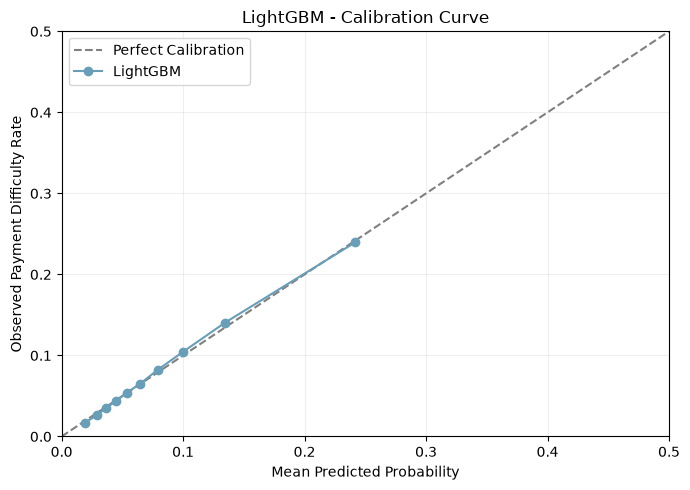

In [81]:
# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_oof,
    p_oof,
    n_bins=10,
    strategy="quantile",
)

# Calculate Brier Scores
model_brier = brier_score_loss(y_oof, p_oof)

baseline_proba = np.full(
    len(y_oof),
    y_oof.mean(),
)

baseline_brier = brier_score_loss(
    y_oof,
    baseline_proba,
)

print(f"Model Brier Score: {model_brier:.4f}")
print(f"Baseline Brier Score: {baseline_brier:.4f}")

# Calibration summary
calibration_df = pd.DataFrame({
    "predicted_probability": prob_pred,
    "observed_difficulty_rate": prob_true,
})

display(calibration_df.round(4))

# Visualization
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration",
)

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    color="#689EB8",
    label="LightGBM",
)

ax.set_xlim(0, 0.5)
ax.set_ylim(0, 0.5)
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Payment Difficulty Rate")
ax.set_title("LightGBM - Calibration Curve")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


#### Probability Calibration — Key Findings

We evaluated the predicted probabilities of the optimized LightGBM model.

**Key Findings**

- The model achieved a Brier Score of 0.0696.
- The baseline Brier Score was 0.0742.
- The calibration curve was close to the ideal diagonal line.
- Predicted probabilities were generally close to observed payment difficulty rates.

**Conclusion**

The model shows good probability calibration in the evaluated range.

Additional calibration is not necessary at this stage.

However, we should check higher-risk predictions and validate calibration on the final holdout dataset.

We will now evaluate how different classification thresholds affect business decisions.



### 7.13. Operational Threshold Assessment

We will evaluate the operational impact of different classification thresholds.

Our goals are to:
- Count true positives, false positives, and false negatives.
- Estimate the percentage of applications flagged for review.
- Compare missed risks and false alerts per 1,000 applications.

We will not select the final threshold without considering business requirements.


In [82]:
threshold_candidates = [0.08, 0.10, 0.12, 0.15]

operational_results = []

for threshold in threshold_candidates:
    predictions = (p_oof >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_oof, predictions, labels=[0, 1]
    ).ravel()

    total = len(y_oof)

    operational_results.append({
        "threshold": threshold,
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "review_rate_pct": (tp + fp) / total * 100,
        "false_alerts_per_1000": fp / total * 1000,
        "missed_cases_per_1000": fn / total * 1000,
    })

operational_df = pd.DataFrame(operational_results)

display(
    operational_df.style.format({
        "threshold": "{:.2f}",
        "true_positive": "{:,.0f}",
        "false_positive": "{:,.0f}",
        "false_negative": "{:,.0f}",
        "review_rate_pct": "{:.2f}%",
        "false_alerts_per_1000": "{:.1f}",
        "missed_cases_per_1000": "{:.1f}",
    })
)

,threshold,true_positive,false_positive,false_negative,review_rate_pct,false_alerts_per_1000,missed_cases_per_1000
0,0.08,"12,822","71,548","7,038",34.30%,290.8,28.6
1,0.10,"10,626","49,943","9,234",24.62%,203.0,37.5
2,0.12,"8,794","35,779","11,066",18.12%,145.4,45.0
3,0.15,"6,623","22,489","13,237",11.83%,91.4,53.8



#### Operational Threshold — Key Findings

We evaluated four classification thresholds using out-of-fold predictions.

**Key Findings**

- A threshold of 0.08 detected 64.56% of positive cases but flagged 34.30% of applications.
- A threshold of 0.10 provided 53.50% recall with a review rate of 24.62%.
- A threshold of 0.12 achieved the highest F1-score among the tested thresholds.
- Higher thresholds reduced false alerts but missed more positive cases.

**Conclusion**

We selected 0.12 as a provisional classification threshold for final evaluation.

This threshold provides a balance between risk detection and review volume based on our development results.

It is not a final business policy. A production threshold should also consider review capacity, financial costs, and business requirements.

We will keep the selected threshold fixed during the final holdout evaluation.



## 8. Final Model Evaluation

### 8.1. Final Model Training and Holdout Evaluation

We will train our selected LightGBM model using the full development dataset.

The model will use:
- 35 selected features.
- The best Optuna parameters.
- A classification threshold of 0.12.

We will evaluate the model on the untouched holdout dataset.

Our main metrics are ROC-AUC, Average Precision, Precision, Recall, F1-score, and Brier Score.

We will not change model settings based on the holdout results.


In [83]:
final_features = candidate_features_35.copy()
final_threshold = 0.12

final_pipeline = Pipeline([
    (
        "prepare",
        FunctionTransformer(
            prepare_lgbm_features,
            validate=False,
        ),
    ),
    (
        "model",
        clone(boosting_models["LightGBM"]).set_params(
            **study.best_params,
            class_weight=None,
        ),
    ),
])

final_pipeline.fit(
    X_train[final_features],
    y_train,
)

print("Final model trained successfully.")
print(f"Training applications: {len(X_train):,}")
print(f"Selected features: {len(final_features)}")
print(f"Classification threshold: {final_threshold:.2f}")

Final model trained successfully.
Training applications: 246,008
Selected features: 35
Classification threshold: 0.12


In [84]:
# Predict holdout probabilities
p_holdout = final_pipeline.predict_proba(
    X_holdout[final_features]
)[:, 1]

# Apply the fixed threshold
y_holdout_pred = (
    p_holdout >= final_threshold
).astype(int)

# Calculate final metrics
holdout_metrics = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "Average Precision",
        "Brier Score",
        "Precision",
        "Recall",
        "F1-Score",
    ],
    "value": [
        roc_auc_score(y_holdout, p_holdout),
        average_precision_score(y_holdout, p_holdout),
        brier_score_loss(y_holdout, p_holdout),
        precision_score(y_holdout, y_holdout_pred),
        recall_score(y_holdout, y_holdout_pred),
        f1_score(y_holdout, y_holdout_pred),
    ],
})

display(
    holdout_metrics.style.format({
        "value": "{:.4f}"
    })
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_holdout,
    y_holdout_pred,
    labels=[0, 1],
).ravel()

holdout_confusion = pd.DataFrame({
    "result": ["TN", "FP", "FN", "TP"],
    "count": [tn, fp, fn, tp],
})

display(holdout_confusion)

print(
    f"Review Rate: "
    f"{(tp + fp) / len(y_holdout) * 100:.2f}%"
)

,metric,value
0,ROC-AUC,0.7350
1,Average Precision,0.2208
2,Brier Score,0.0690
3,Precision,0.2035
4,Recall,0.4669
5,F1-Score,0.2834


,result,count
0,TN,47463
1,FP,9075
2,FN,2647
3,TP,2318


Review Rate: 18.52%



#### Final Holdout Evaluation — Key Findings

We evaluated the optimized LightGBM model on 61,503 unseen applications.

The model uses 35 selected features and a fixed classification threshold of 0.12.

**Key Findings**

- ROC-AUC reached 0.7350, compared with 0.7254 during development.
- Average Precision reached 0.2208, compared with 0.2077 during development.
- The model correctly identified 2,318 applicants with payment difficulty.
- Recall was 46.69%, while precision was 20.35%.
- Approximately 18.52% of applications were flagged for review.
- The Brier Score was 0.0690.

**Conclusion**

The final model achieved better ranking performance on the holdout set than during cross-validation.

This is a positive sign for model generalization.

However, the model still misses many applicants with payment difficulty and produces false positive alerts.

The model may be useful for risk scoring and manual review prioritization, but it is not ready for automatic credit decisions.

Before deployment, we must verify that all historical features were available at application time.

We will keep the final model parameters and classification threshold unchanged.



## 9. Model Deployment Preparation

### 9.1. Final Feature Contract

We will document the input features required by our final model.

Our goals are to:
- List the 35 selected features.
- Identify features available in SQL Server.
- Identify features created in Python.
- Prepare a consistent feature definition for future predictions.

The same feature definitions must be used during training and inference.


In [85]:

feature_contract = pd.DataFrame({
    "feature": final_features,
    "source": [
        "Python Engineered"
        if col not in df.columns
        else "SQL Applicant Overview"
        for col in final_features
    ],
    "dtype": [
        str(X_train[col].dtype)
        for col in final_features
    ],
    "missing_pct": [
        X_train[col].isna().mean() * 100
        for col in final_features
    ],
})

display(feature_contract.round(2))

print("\nFeature source summary:")
display(feature_contract["source"].value_counts())

assert len(feature_contract) == 35
assert feature_contract["feature"].is_unique


,feature,source,dtype,missing_pct
0,ANNUITY_CREDIT_RATIO,SQL Applicant Overview,float64,0.00
1,DAYS_EMPLOYED,SQL Applicant Overview,float64,18.02
2,BUREAU_DEBT_CREDIT_RATIO,SQL Applicant Overview,float64,14.71
3,CREDIT_GOODS_RATIO,Python Engineered,float64,0.09
4,DAYS_SINCE_MOST_RECENT_BUREAU_CREDIT,SQL Applicant Overview,float64,14.35
5,LATE_PAYMENT_RATE,SQL Applicant Overview,float64,5.16
6,PREVIOUS_REFUSAL_RATE,Python Engineered,float64,5.35
7,AGE_YEARS,SQL Applicant Overview,float64,0.00
8,TOTAL_ACTUAL_PAYMENT,SQL Applicant Overview,float64,5.16
9,AVG_CREDIT_UTILIZATION,SQL Applicant Overview,float64,72.04



Feature source summary:


source
SQL Applicant Overview    31
Python Engineered          4
Name: count, dtype: int64


### 9.2. SQL Feature View

We created a SQL view to generate the 35 features required by our final model.

The view includes:
- Training applications.
- Test applications.
- Four engineered financial and historical features.

The same feature definitions will be used for training and inference.

This approach will help us generate predictions for new applications without manually creating each feature.



### 9.3. Python-SQL Feature Parity Test

We will compare the final model features generated by Python and SQL Server.

Our goals are to:
- Validate all 35 feature names.
- Compare numerical and categorical values.
- Check missing value consistency.
- Confirm that engineered features use the same calculations.

We will use a sample from the development dataset.

This test helps us ensure consistent inputs during training and inference.


In [87]:
# Select a reproducible sample from development data
sample_indices = X_train.sample(
    n=1000,
    random_state=42,
).index

python_sample = df_fe.loc[
    sample_indices,
    ["SK_ID_CURR", *final_features],
].copy()

applicant_ids = (
    python_sample["SK_ID_CURR"].astype(int).tolist()
)

# Load the same applicants from SQL Server
query = text("""
    SELECT *
    FROM ml.vw_default_risk_features
    WHERE DATASET_TYPE = 'TRAIN'
      AND SK_ID_CURR IN :applicant_ids;
""").bindparams(
    bindparam("applicant_ids", expanding=True)
)

with engine.connect() as connection:
    sql_sample = pd.read_sql_query(
        query,
        connection,
        params={"applicant_ids": applicant_ids},
    )

# Validate SQL schema and applicant IDs
sql_features = set(sql_sample.columns) - {
    "SK_ID_CURR", "DATASET_TYPE", "TARGET"
}

assert sql_features == set(final_features)
assert sql_sample["SK_ID_CURR"].is_unique
assert len(sql_sample) == len(python_sample)

print(f"Python applicants: {len(python_sample):,}")
print(f"SQL applicants: {len(sql_sample):,}")
print(f"Validated feature names: {len(sql_features)}")

Python applicants: 1,000
SQL applicants: 1,000
Validated feature names: 35


In [88]:

parity_df = python_sample.merge(
    sql_sample[["SK_ID_CURR", *final_features]],
    on="SK_ID_CURR",
    how="inner",
    suffixes=("_python", "_sql"),
    validate="one_to_one",
)

parity_results = []

for feature in final_features:
    py_values = parity_df[f"{feature}_python"]
    sql_values = parity_df[f"{feature}_sql"]

    missing_mismatch = (
        py_values.isna() != sql_values.isna()
    ).sum()

    if feature == "NAME_CONTRACT_TYPE":
        same_values = (
            py_values.eq(sql_values).fillna(False)
            | (py_values.isna() & sql_values.isna())
        ).to_numpy(dtype=bool)
    else:
        py_numeric = pd.to_numeric(
            py_values, errors="raise"
        ).astype(float)

        sql_numeric = pd.to_numeric(
            sql_values, errors="raise"
        ).astype(float)

        same_values = np.isclose(
            py_numeric,
            sql_numeric,
            rtol=1e-6,
            atol=1e-6,
            equal_nan=True,
        )

    parity_results.append({
        "feature": feature,
        "value_mismatches": int((~same_values).sum()),
        "missing_mismatches": int(missing_mismatch),
    })

parity_summary = pd.DataFrame(parity_results)

print(f"Compared features: {len(parity_summary)}")
print(
    "Total value mismatches:",
    parity_summary["value_mismatches"].sum()
)
print(
    "Total missing mismatches:",
    parity_summary["missing_mismatches"].sum()
)

display(
    parity_summary[
        (parity_summary["value_mismatches"] > 0)
        | (parity_summary["missing_mismatches"] > 0)
    ]
)


Compared features: 35
Total value mismatches: 0
Total missing mismatches: 0


,feature,value_mismatches,missing_mismatches



#### Feature Parity — Key Findings

We compared 35 features for 1,000 applications using Python and SQL Server.

**Key Findings**

- All 35 feature names matched.
- No value differences were detected.
- No missing value differences were found.
- SQL and Python calculations were consistent in the tested sample.

**Conclusion**

The feature parity test passed.

The SQL feature view can provide consistent inputs for our trained model.

Before production use, we must also verify historical data availability at application time.


In [91]:
project_root = Path(env_path).resolve().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.default_risk.preprocessing import prepare_lgbm_features

print(f"Function module: {prepare_lgbm_features.__module__}")


Function module: src.default_risk.preprocessing



### 9.4. Saving and Loading the Final Model

We will save our trained LightGBM model using Joblib.

The model artifact will include:
- The preprocessing pipeline.
- The 35 selected features.
- The classification threshold.
- Model version information.

We will reload the saved model and compare its predictions with the original model.

This step will help us use the model in future applications.


In [92]:
# Rebuild the final pipeline with the imported function
final_pipeline = Pipeline([
    (
        "prepare",
        FunctionTransformer(
            prepare_lgbm_features,
            validate=False,
        ),
    ),
    (
        "model",
        clone(boosting_models["LightGBM"]).set_params(
            **study.best_params,
            class_weight=None,
        ),
    ),
])

# Fit on the full development dataset
final_pipeline.fit(
    X_train[final_features],
    y_train,
)

# Save the model artifact
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "default_risk_lgbm.joblib"

model_artifact = {
    "pipeline": final_pipeline,
    "features": final_features.copy(),
    "threshold": final_threshold,
    "model_name": "LightGBM",
    "model_version": "1.0.0",
}

joblib.dump(model_artifact, model_path, compress=3)

print(f"Model saved: {model_path}")
print(f"Feature count: {len(final_features)}")
print(f"Threshold: {final_threshold}")

Model saved: C:\Users\okand\Desktop\Projects\home-credit-risk-platform\models\default_risk_lgbm.joblib
Feature count: 35
Threshold: 0.12


In [93]:
# Load the saved model
loaded_artifact = joblib.load(model_path)

# Use development data for the loading test
sample = X_train[final_features].head(10).copy()

original_proba = final_pipeline.predict_proba(sample)[:, 1]

loaded_proba = loaded_artifact["pipeline"].predict_proba(
    sample[loaded_artifact["features"]]
)[:, 1]

np.testing.assert_allclose(
    original_proba,
    loaded_proba,
    rtol=1e-10,
    atol=1e-10,
)

assert loaded_artifact["features"] == final_features
assert loaded_artifact["threshold"] == final_threshold

print("Model loading test passed.")
print("Predictions are identical.")

display(
    pd.DataFrame({
        "original_probability": original_proba,
        "loaded_probability": loaded_proba,
    })
)

Model loading test passed.
Predictions are identical.


,original_probability,loaded_probability
0,0.08,0.08
1,0.06,0.06
2,0.30,0.30
3,0.28,0.28
4,0.21,0.21
5,0.04,0.04
6,0.11,0.11
7,0.06,0.06
8,0.09,0.09
9,0.09,0.09


In [94]:

import json

# Save the approved model configuration
model_config = {
    "features": final_features,
    "threshold": final_threshold,
    "best_params": study.best_params,
    "model_version": "1.0.0",
}

config_path = (
    project_root / "src" / "default_risk" / "model_config.json"
)

config_path.write_text(
    json.dumps(model_config, indent=4),
    encoding="utf-8",
)

# Save the exact development applicant IDs
split_path = (
    project_root / "data" / "processed"
    / "default_risk_development_ids.csv"
)

split_path.parent.mkdir(parents=True, exist_ok=True)

development_ids = df_fe.loc[
    X_train.index, ["SK_ID_CURR"]
]

development_ids.to_csv(split_path, index=False)

print(f"Config saved: {config_path.name}")
print(f"Development IDs saved: {len(development_ids):,}")


Config saved: model_config.json
Development IDs saved: 246,008



### 9.5. Reproducible Model Training

We created a Python training script for the final LightGBM model.

The script:
- Loads the selected features from the model configuration.
- Reads training data from SQL Server.
- Uses the original development applications.
- Trains the model with the selected hyperparameters.
- Saves the trained pipeline as a Joblib artifact.

This allows us to retrain the model without running the full notebook.



### 9.6. Reproducible Model Evaluation

We created a separate Python script to evaluate the saved model.

The script:
- Loads the trained LightGBM pipeline.
- Reads the original holdout applications from SQL Server.
- Calculates classification and probability metrics.
- Reports the confusion matrix.

We will compare these results with the notebook evaluation to confirm reproducibility.



#### SQL Prediction — Key Findings

We successfully generated a risk prediction using SQL Server and the saved LightGBM pipeline.

**Key Findings**

- The applicant's predicted payment difficulty probability was 1.68%.
- The classification threshold was 12%.
- The model returned Risk Flag = 0.
- We fixed a data type issue in the preprocessing module.
- The prediction pipeline now works with a single applicant.

**Conclusion**

The SQL-based prediction workflow is working correctly for the tested applicant.

We will verify that the preprocessing update does not change the model's evaluation results.

Next, we will extend the prediction workflow to multiple applications.



### 9.8. Batch Prediction

We created a batch prediction script for unlabeled applications.

The script:
- Loads the saved LightGBM model.
- Reads TEST applications from SQL Server.
- Predicts payment difficulty probabilities.
- Applies the selected review threshold.
- Saves the results as a CSV file.

These predictions do not have actual target labels, so we cannot calculate classification performance metrics.

The results can be used for risk analysis and manual review prioritization.



### 9.9. Storing Model Predictions in SQL Server

We generated risk predictions for 48,744 unlabeled TEST applications.

**Key Findings**

- 8,972 applications were flagged for manual review.
- The review rate was 18.41%.
- The average predicted risk probability was 7.91%.
- Prediction results were prepared for storage in SQL Server.

**Conclusion**

The batch prediction workflow supports risk monitoring and downstream reporting. Actual default outcomes are not available for the TEST dataset, so prediction accuracy cannot be evaluated on these records.



### 9.10. ML Risk Reporting Data

We created a SQL reporting view that combines model predictions with applicant characteristics and historical financial behavior.

**Key Findings**

- The batch prediction process generated 48,744 risk scores.
- A total of 8,972 applications were flagged for review.
- The review rate was 18.41%.
- The average predicted risk probability was 7.91%.

**Conclusion**

The SQL reporting view provides a structured data source for Power BI risk monitoring and exploratory analysis.

Predicted risk scores should be interpreted as model estimates, not confirmed default outcomes. The model is not yet validated for operational credit decisions.
